# Task B04: HMDA 2024 Data Quality Assessment & Raw Ingestion

**Course:** Big Data Analysis (Final Project)  
**Group:** Group 3  
**Topic:** Decomposing Racial Gaps in Mortgage Denial Rates: A Large-Scale Analysis of the 2024 U.S. HMDA Market  
**Companion Documents:** `data_quality_assessment_plan.md`, `data_cleaning_rules.md`, `Coding and documenting conventions.md`  

---

### Objectives
1. **Ingest & Traceability:** Stream the 4.32 GB raw CSV file (`2024_public_lar_one_year_csv.csv`), retain all 99 fields as strings without loss of leading zeros or special codes (`na_values=[]`), and append technical columns (`row_id` and deterministic hash `bucket`).
2. **Source Profiling (Step 0):** Document source metadata, exact row counts, and checksums.
3. **Data Quality Audits (Steps 1 to 7):** Profile completeness (distinguishing Blank `""` vs. `NA`, `Exempt`, `1111`, `8888`, `9999`), identifier formats (V06), allowed code validity, range compliance (V01-V05), cross-field consistency (V07, V08), duplicate patterns (V10), and distribution percentiles.
4. **Ledger & Artifact Exports (Step 8):** Export comprehensive diagnostic profile tables to `output/` to serve as verified empirical inputs for the cleaning rulebook (`data_cleaning_rules.md`).

## Section 1: Configuration & Environment Setup

- **Input:** System libraries, project directory paths, and raw data paths.
- **Process:**
  - Configure multi-user environment path resolution via `os.environ.get('HMDA_ROOT', ...)`.
  - Initialize data manipulation packages (`pandas`, `numpy`, `pyarrow`).
  - Configure **DuckDB**: an embedded, in-process analytical SQL engine that executes queries directly on Parquet files using vectorized multi-threading without loading the full 12M rows into memory. We set `PRAGMA memory_limit = '8GB'` and define `temp_directory` in `output/duckdb_temp` to ensure spill-to-disk stability for wide 99-column aggregations.
  - Define canonical sentinel values tuple: `SENTINELS = ('', 'NA', 'Exempt', '1111')` used universally across all SQL and validation queries.
  - Define `FORCE_REINGEST` flag (default `False`) to prevent rebuilding the 4 GB Parquet on every run.
  - Verify existence of raw data and data dictionary before proceeding.
- **Output:** Fully configured runtime environment with validated file accessibility.

In [ ]:
# Step 1: Standard library and data manipulation imports
import os, re, time
from pathlib import Path
import duckdb, numpy as np, pandas as pd
import pyarrow as pa, pyarrow.parquet as pq
import matplotlib.pyplot as plt, seaborn as sns

# Step 2: Configure display, paths and DuckDB guards
pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
sns.set_theme(style='whitegrid', font_scale=1.0)
np.random.seed(42)

# [CHANGE] Step 2: paths. HMDA_ROOT env var, else nearest parent folder that contains 'origin/'
_env = os.environ.get('HMDA_ROOT')
PROJECT_ROOT = Path(_env) if _env else next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'origin').exists()), None)
assert PROJECT_ROOT is not None, "Set HMDA_ROOT, or run inside the project folder (the one containing 'origin/')"
OUTPUT_DIR = PROJECT_ROOT / 'B04 - 30 Oct' / 'output'
ORIGIN_DIR = PROJECT_ROOT / 'origin'
RAW_CSV_PATH = PROJECT_ROOT / 'data' / 'raw' / '2024_public_lar_one_year_csv.csv' if (PROJECT_ROOT / 'data' / 'raw' / '2024_public_lar_one_year_csv.csv').exists() else PROJECT_ROOT / '2024_public_lar_one_year_csv.csv'
RAW_PARQUET_PATH = OUTPUT_DIR / 'B04_raw_with_buckets.parquet'
DATA_DICT_PATH = ORIGIN_DIR / 'HMDA_Public_LAR_Data_Dictionary.xlsx'
FORCE_REINGEST = False

assert RAW_CSV_PATH.exists() and DATA_DICT_PATH.exists(), 'Source files missing'
duck_temp_dir = OUTPUT_DIR / 'duckdb_temp'
duck_temp_dir.mkdir(parents=True, exist_ok=True)

duck_conn = duckdb.connect()
duck_conn.execute("PRAGMA memory_limit = '8GB'")
duck_conn.execute(f"PRAGMA temp_directory = '{duck_temp_dir.as_posix()}'")

SENTINELS = ('', 'NA', 'Exempt', '1111')       # coded / identifier columns
SENTINELS_NUM = ('', 'NA', 'Exempt')           # numeric columns: 1111 is a real value, not a code

print(f'Project root       : {PROJECT_ROOT}')
print(f'Target Raw Parquet : {RAW_PARQUET_PATH}')

Project root       : D:\H-NEU\004\44 - Big Data\Final project
Target Raw Parquet : D:\H-NEU\004\44 - Big Data\Final project\B04 - 30 Oct\output\B04_raw_with_buckets.parquet


## Section 2: Step 0 - Source Profile & Pre-Ingest Verification

- **Input:** Source CSV file `2024_public_lar_one_year_csv.csv`.
- **Process:** Measure file size on disk, count exact records via DuckDB parser (handling quoted fields with embedded linebreaks), and extract the 99 header column names.
- **Output:** Standardized Source Profile metadata table ready for the technical report appendix.

In [3]:
# Step 1: Measure file size and check CSV basic attributes
csv_size_bytes = RAW_CSV_PATH.stat().st_size
csv_size_gb = csv_size_bytes / (1024**3)

# Step 2: Use DuckDB for an exact record count on the raw CSV
t0 = time.time()
total_rows = duck_conn.execute(f"SELECT count(*) FROM read_csv_auto('{RAW_CSV_PATH.as_posix()}')").fetchone()[0]
count_duration = time.time() - t0

# Step 3: Extract and inspect header column names
with open(RAW_CSV_PATH, 'r', encoding='utf-8') as f:
    header_line = f.readline().strip()
header_cols = [c.strip() for c in header_line.split(',')]

# Step 4: Display source profile summary table
source_profile = pd.DataFrame([
    {'Attribute': 'Source File Name', 'Value': RAW_CSV_PATH.name},
    {'Attribute': 'File Size (Bytes)', 'Value': f'{csv_size_bytes:,} bytes'},
    {'Attribute': 'File Size (GB)', 'Value': f'{csv_size_gb:.2f} GB'},
    {'Attribute': 'Exact Record Count', 'Value': f'{total_rows:,} applications'},
    {'Attribute': 'Header Field Count', 'Value': f'{len(header_cols)} fields'},
    {'Attribute': 'Reporting Year', 'Value': '2024 (Mandatory)'},
    {'Attribute': 'Unit of Observation', 'Value': 'One loan application record'},
    {'Attribute': 'DuckDB Count Duration', 'Value': f'{count_duration:.2f} seconds'}
])
display(source_profile)

,Attribute,Value
0,Source File Name,2024_public_lar_one_year_csv.csv
1,File Size (Bytes),"4,636,628,799 bytes"
2,File Size (GB),4.32 GB
3,Exact Record Count,"12,259,199 applications"
4,Header Field Count,99 fields
5,Reporting Year,2024 (Mandatory)
6,Unit of Observation,One loan application record
7,DuckDB Count Duration,6.10 seconds


### Technical Detail: Knuth Multiplicative Multiplier for Deterministic Subsampling

**Why this technique is used:**
The project requires benchmarking Pandas vs. PySpark across multiple sample sizes (25%, 50%, 100%). To ensure both engines process **strictly identical subsets** without coordinating pseudo-random number generator (PRNG) seeds, each row is assigned a deterministic `bucket` $\in [0, 99]$ based on its `row_id`:
$$\text{bucket} = (\text{row\_id} \times 2654435761) \pmod{100}$$
where $2654435761 \approx 2^{32} / \phi$ (Knuth golden ratio constant). In modulo 100 arithmetic, this simplifies to $(61 \times \text{row\_id}) \pmod{100}$ because $2654435761 \equiv 61 \pmod{100}$. Because $\gcd(61, 100) = 1$, every block of 100 consecutive records generates an exact, uniform permutation of all 100 buckets. Across the 12,259,199 rows ($12,259,199 \equiv 99 \pmod{100}$), exactly 99 buckets have 122,592 records and 1 bucket has 122,591 records (maximum spread $\le 1$). In PySpark, this is identical via `(F.col('row_id') * 2654435761) % 100`.

In [4]:
def compute_knuth_bucket(row_ids: np.ndarray) -> np.ndarray:
    """
    Maps an array of 0-based integer row IDs to deterministic buckets [0, 99].
    
    Parameters
    ----------
    row_ids : np.ndarray
        1D array of 64-bit integer row indices.
        
    Returns
    -------
    np.ndarray
        1D array of int8 bucket values in the range [0, 99].
    """
    KNUTH_CONSTANT = np.int64(2654435761)
    return ((row_ids * KNUTH_CONSTANT) % 100).astype(np.int8)

# Step 1: Verify uniformity on a test array of 100,000 indices
test_ids = np.arange(100_000, dtype=np.int64)
test_buckets = compute_knuth_bucket(test_ids)
b_counts = pd.Series(test_buckets).value_counts()
print(f'Verification: Min count per bucket: {b_counts.min():,}, Max count: {b_counts.max():,}')
print(f'Sample first 10 buckets: {test_buckets[:10].tolist()}')

Verification: Min count per bucket: 1,000, Max count: 1,000
Sample first 10 buckets: [0, 61, 22, 83, 44, 5, 66, 27, 88, 49]


In [5]:
import duckdb
import pandas as pd
from pathlib import Path

# Path to the ingested parquet file
parquet_path = Path("B04 - 30 Oct/output/B04_raw_with_buckets.parquet")
if not parquet_path.exists():
    parquet_path = Path("output/B04_raw_with_buckets.parquet")

con = duckdb.connect()
path_str = str(parquet_path).replace("\\", "/")

# -------------------------------------------------------------------------
# Example 1: Inspect the first 10 rows showing row_id and deterministic bucket
# -------------------------------------------------------------------------
print("--- 1. FIRST 10 ROWS IN THE DATASET ---")
query_head = f"""
    SELECT 
        row_id,
        bucket,
        -- Demonstration of Knuth formula: (row_id * 61) % 100
        (row_id * 61) % 100 AS formula_check,
        action_taken,
        loan_amount
    FROM read_parquet('{path_str}')
    LIMIT 10
"""
df_head = con.execute(query_head).df()
display(df_head)

# -------------------------------------------------------------------------
# Example 2: Verify uniform bucket distribution across all 12.25M records
# -------------------------------------------------------------------------
print("\n--- 2. BUCKET UNIFORMITY METRICS (100 BUCKETS TOTAL) ---")
query_uniformity = f"""
    SELECT 
        min(row_count) AS min_records_per_bucket,
        max(row_count) AS max_records_per_bucket,
        avg(row_count) AS avg_records_per_bucket,
        max(row_count) - min(row_count) AS max_difference
    FROM (
        SELECT bucket, count(*) AS row_count
        FROM read_parquet('{path_str}')
        GROUP BY bucket
    )
"""
df_uniformity = con.execute(query_uniformity).df()
display(df_uniformity)

# -------------------------------------------------------------------------
# Example 3: Demonstrate strictly nested sample extraction (25% vs 50%)
# -------------------------------------------------------------------------
print("\n--- 3. SAMPLE SIZES FOR BENCHMARK EXPERIMENTS ---")
query_samples = f"""
    SELECT 
        '25% Sample (bucket < 25)' AS sample_name,
        count(*) AS total_rows,
        round(count(*) * 100.0 / 12259199, 2) AS pct_of_dataset
    FROM read_parquet('{path_str}')
    WHERE bucket < 25
    UNION ALL
    SELECT 
        '50% Sample (bucket < 50)' AS sample_name,
        count(*) AS total_rows,
        round(count(*) * 100.0 / 12259199, 2) AS pct_of_dataset
    FROM read_parquet('{path_str}')
    WHERE bucket < 50
    UNION ALL
    SELECT 
        '100% Sample (Full)' AS sample_name,
        count(*) AS total_rows,
        100.00 AS pct_of_dataset
    FROM read_parquet('{path_str}')
"""
df_samples = con.execute(query_samples).df()
display(df_samples)

--- 1. FIRST 10 ROWS IN THE DATASET ---


,row_id,bucket,formula_check,action_taken,loan_amount
0,0,0,0,6,275000
1,1,61,61,6,315000
2,2,22,22,6,705000
3,3,83,83,6,245000
4,4,44,44,6,325000
5,5,5,5,6,215000
6,6,66,66,6,245000
7,7,27,27,6,205000
8,8,88,88,6,745000
9,9,49,49,6,295000



--- 2. BUCKET UNIFORMITY METRICS (100 BUCKETS TOTAL) ---


,min_records_per_bucket,max_records_per_bucket,avg_records_per_bucket,max_difference
0,122591,122592,"122,591.9900",1



--- 3. SAMPLE SIZES FOR BENCHMARK EXPERIMENTS ---


,sample_name,total_rows,pct_of_dataset
0,25% Sample (bucket < 25),3064800,25.0000
1,50% Sample (bucket < 50),6129599,50.0000
2,100% Sample (Full),12259199,100.0000


## Section 2.1: Chunked Ingestion to Raw Parquet (`B04_raw_with_buckets.parquet`)

- **Input:** Source CSV (`2024_public_lar_one_year_csv.csv`), `CHUNK_SIZE = 500,000`.
- **Process:**
  - Read CSV with `dtype=str`, `keep_default_na=False`, `na_values=[]`. Blank cells remain empty strings `""`, preventing PyArrow from inferring type `null` on fully empty columns in later chunks (such as `co_applicant_ethnicity_5`).
  - Enforce explicit `FIXED_SCHEMA` (all 99 original columns as `pa.string()`, plus `row_id` as `pa.int64()` and `bucket` as `pa.int8()`).
  - Stream chunks to a temporary file (`.tmp`) and atomically replace `RAW_PARQUET_PATH` upon successful completion to prevent leaving a corrupted file if interrupted.
  - If `RAW_PARQUET_PATH` already exists and `FORCE_REINGEST = False`, skip ingestion to save processing time.
- **Output:** Persisted `output/B04_raw_with_buckets.parquet` with verified dimensions and size.

In [6]:
# Step 1: Define fixed schema (99 string columns + 2 technical columns)
FIXED_SCHEMA = pa.schema([pa.field(c, pa.string()) for c in header_cols] +
                         [pa.field('row_id', pa.int64()), pa.field('bucket', pa.int8())])
tmp_path = RAW_PARQUET_PATH.with_suffix('.tmp')

# Step 2: Conditionally ingest or reuse existing Parquet
if RAW_PARQUET_PATH.exists() and not FORCE_REINGEST:
    print(f'Parquet file already exists at {RAW_PARQUET_PATH} - skipping ingestion.')
    current_row = total_rows
else:
    tmp_path.unlink(missing_ok=True)
    CHUNK_SIZE = 500_000
    reader = pd.read_csv(RAW_CSV_PATH, dtype=str, keep_default_na=False, na_values=[], encoding='utf-8', chunksize=CHUNK_SIZE, low_memory=False)
    current_row, t_start = 0, time.time()
    total_chunks = (total_rows + CHUNK_SIZE - 1) // CHUNK_SIZE
    print(f'Streaming CSV to temporary Parquet ({total_chunks} chunks, {total_rows:,} rows)...')
    with pq.ParquetWriter(tmp_path, FIXED_SCHEMA, compression='zstd') as writer:
        for i, chunk in enumerate(reader):
            n_chunk = len(chunk)
            ids = np.arange(current_row, current_row + n_chunk, dtype=np.int64)
            chunk['row_id'], chunk['bucket'] = ids, compute_knuth_bucket(ids)
            writer.write_table(pa.Table.from_pandas(chunk, schema=FIXED_SCHEMA, preserve_index=False))
            current_row += n_chunk
            print(f'Chunk {i+1:2d}/{total_chunks} | Written {current_row:,} rows ({(current_row/total_rows)*100:.1f}%)')
    tmp_path.replace(RAW_PARQUET_PATH)
    print(f'Ingestion completed in {time.time()-t_start:.1f}s.')

# Step 3: Log output file metrics
parquet_size_mb = RAW_PARQUET_PATH.stat().st_size / (1024**2)
print(f'Output file: {RAW_PARQUET_PATH} ({parquet_size_mb:.2f} MB | {current_row:,} rows)')

Parquet file already exists at D:\H-NEU\004\44 - Big Data\Final project\B04 - 30 Oct\output\B04_raw_with_buckets.parquet - skipping ingestion.
Output file: D:\H-NEU\004\44 - Big Data\Final project\B04 - 30 Oct\output\B04_raw_with_buckets.parquet (432.33 MB | 12,259,199 rows)


## Section 2.2: Post-Ingest Verification Checklist

- **Input:** Persisted Parquet file `output/B04_raw_with_buckets.parquet`.
- **Process:** Execute the 6-point verification checklist specified in Section 4 of `data_quality_assessment_plan.md` using real evaluative conditions:
  1. Exact row count reconciliation ($12,259,199$).
  2. Total column count check ($99 \text{ original} + \text{row\_id} + \text{bucket} = 101$).
  3. Schema type check: all 99 original columns remain string (`pa.string()`).
  4. Bucket uniformity: maximum difference across all 100 buckets is $\le 1$.
  5. Row ID continuity: `min(row_id) == 0`, `max(row_id) == total_rows - 1`, and `count(DISTINCT row_id) == total_rows`.
  6. Literal `"NA"` preservation without silent coercion to `NaN`.
- **Output:** Verification assertion status table.

In [7]:
# Step 1: Open Parquet file metadata and read audit statistics
pq_meta = pq.read_metadata(RAW_PARQUET_PATH)
parquet_path_str = str(RAW_PARQUET_PATH).replace('\\', '/')

audit_row_count = duck_conn.execute(f"SELECT count(*) FROM read_parquet('{parquet_path_str}')").fetchone()[0]
audit_col_count = pq_meta.num_columns

# Step 2: Compute real evaluative conditions
rid_stats = duck_conn.execute(f"""
    SELECT min(row_id) AS min_r, max(row_id) AS max_r, count(DISTINCT row_id) AS dist_r 
    FROM read_parquet('{parquet_path_str}')
""").fetchone()

b_stats = duck_conn.execute(f"""
    SELECT min(cnt) AS min_c, max(cnt) AS max_c 
    FROM (SELECT count(*) AS cnt FROM read_parquet('{parquet_path_str}') GROUP BY bucket)
""").fetchone()

arrow_schema = pq_meta.schema.to_arrow_schema()
non_string_cols = [f.name for f in arrow_schema if f.name in header_cols and f.type != pa.string()]
na_count = duck_conn.execute(f"SELECT count(*) FROM read_parquet('{parquet_path_str}') WHERE income = 'NA'").fetchone()[0]

# Step 3: Format verification checklist table
checklist_df = pd.DataFrame([
    {'Criterion': '1. Row count equals source CSV', 'Target': f'{total_rows:,}', 'Observed': f'{audit_row_count:,}', 'Status': 'PASS' if audit_row_count == total_rows else 'FAIL'},
    {'Criterion': '2. Total columns (99 original + 2 technical)', 'Target': '101', 'Observed': str(audit_col_count), 'Status': 'PASS' if audit_col_count == 101 else 'FAIL'},
    {'Criterion': '3. All 99 original columns remain string', 'Target': '0 non-string cols', 'Observed': f'{len(non_string_cols)} non-string', 'Status': 'PASS' if len(non_string_cols) == 0 else 'FAIL'},
    {'Criterion': '4. Bucket uniformity (max_c - min_c <= 1)', 'Target': '<= 1 difference', 'Observed': f'Min: {b_stats[0]:,} | Max: {b_stats[1]:,} (Diff: {b_stats[1]-b_stats[0]})', 'Status': 'PASS' if (b_stats[1] - b_stats[0]) <= 1 else 'FAIL'},
    {'Criterion': '5. Row ID continuous (0 to N-1, distinct)', 'Target': f'(0, {total_rows-1:,}, {total_rows:,})', 'Observed': f'({rid_stats[0]}, {rid_stats[1]:,}, {rid_stats[2]:,})', 'Status': 'PASS' if rid_stats == (0, total_rows-1, total_rows) else 'FAIL'},
    {'Criterion': '6. Literal NA strings preserved (e.g. income=\'NA\')', 'Target': '> 0 rows', 'Observed': f'{na_count:,} rows', 'Status': 'PASS' if na_count > 0 else 'FAIL'}
])
display(checklist_df)

,Criterion,Target,Observed,Status
0,1. Row count equals source CSV,"12,259,199","12,259,199",PASS
1,2. Total columns (99 original + 2 technical),101,101,PASS
2,3. All 99 original columns remain string,0 non-string cols,0 non-string,PASS
3,4. Bucket uniformity (max_c - min_c <= 1),<= 1 difference,"Min: 122,591 | Max: 122,592 (Diff: 1)",PASS
4,"5. Row ID continuous (0 to N-1, distinct)","(0, 12,259,198, 12,259,199)","(0, 12,259,198, 12,259,199)",PASS
5,6. Literal NA strings preserved (e.g. income='...,> 0 rows,"1,780,434 rows",PASS


## Section 3: Step 1 - Column Catalog & Analytical Tiers

- **Input:** Data Dictionary (`HMDA_Public_LAR_Data_Dictionary.xlsx`).
- **Process:** Map the 99 fields into 3 analytical tiers based on the Group 3 Research Proposal:
  - **Tier 1 (Core RQ Variables, 18 fields):** Key variables required for the main sequential decomposition (outcomes, demographics, loan products, core financials, geography, lender).
  - **Tier 2 (Supporting Controls & Filters, 24 fields):** Variables supporting sample filtering (F02 commercial, F03 reverse mortgage), range checks (V01-V05), pricing, tract attributes, and AUS.
  - **Tier 3 (Auxiliary & Extended Demographic Details, 57 fields):** Variables containing secondary repeated race/ethnicity fields, secondary denial reasons, and metadata.
  - Assert strict mathematical equality: $18 + 24 + 57 = 99$, with zero overlaps and full membership in the dictionary.
- **Output:** Analytical Tier breakdown and cross-tabulation table.

In [8]:
# Step 1: Read Data Dictionary sheets from Excel
dict_df = pd.read_excel(DATA_DICT_PATH, sheet_name='Data_Dictionary')
dict_field_set = set(dict_df['Field Name'])

# Step 2: Define research question tiers based on Group 3 proposal
tier_1_cols = ['action_taken', 'derived_race', 'derived_ethnicity', 'derived_sex',
               'loan_type', 'loan_purpose', 'lien_status', 'occupancy_type',
               'debt_to_income_ratio', 'combined_loan_to_value_ratio', 'income', 'loan_amount',
               'denial_reason_1', 'state_code', 'derived_msa_md', 'census_tract',
               'tract_to_msa_income_percentage', 'lei']
tier_2_cols = ['business_or_commercial_purpose', 'reverse_mortgage', 'open_end_line_of_credit',
               'property_value', 'loan_term', 'interest_rate', 'rate_spread', 'total_loan_costs',
               'total_points_and_fees', 'origination_charges', 'discount_points', 'lender_credits',
               'applicant_age', 'co_applicant_age', 'applicant_credit_score_type', 'co_applicant_credit_score_type',
               'conforming_loan_limit', 'derived_dwelling_category', 'derived_loan_product_type',
               'tract_population', 'tract_minority_population_percent', 'ffiec_msa_md_median_family_income',
               'aus_1', 'county_code']

# Step 3: Validate tier lists with programmatic assertions
assert len(tier_1_cols) == 18 and len(tier_2_cols) == 24
assert set(tier_1_cols).issubset(dict_field_set) and set(tier_2_cols).issubset(dict_field_set)
assert len(set(tier_1_cols) & set(tier_2_cols)) == 0, 'Overlap between Tier 1 and Tier 2'

def assign_tier(col_name):
    if col_name in tier_1_cols: return 'Tier 1: Core RQ Variables'
    if col_name in tier_2_cols: return 'Tier 2: Supporting & Controls'
    return 'Tier 3: Auxiliary & Demographics'

dict_df['Analysis_Tier'] = dict_df['Field Name'].apply(assign_tier)
assert (dict_df['Analysis_Tier'] == 'Tier 3: Auxiliary & Demographics').sum() == 57
assert dict_df['Analysis_Tier'].notna().all() and len(dict_df) == 99
display(dict_df.groupby(['Analysis_Tier', 'Trục phân tích']).size().unstack(fill_value=0))

Trục phân tích,1. Tiếp nhận hồ sơ (Application),2. Thẩm định (Underwriting),3. Ra quyết định (Decisioning),4. Thị trường thứ cấp (Secondary market),5. Nhân khẩu học (Demographic),6. Địa lý (Geographic),7. Định danh (Identifier),8. Cột phái sinh (Derived)
Analysis_Tier,,,,,,,,
Tier 1: Core RQ Variables,5,3,2,0,0,3,1,4
Tier 2: Supporting & Controls,3,4,8,0,2,4,0,3
Tier 3: Auxiliary & Demographics,8,4,10,1,30,3,1,0


## Section 3.1: Header Reconciliation Check

- **Input:** 99 CSV header fields vs. 99 Data Dictionary fields.
- **Process:** Verify exact 1-to-1 set equality and sequential ordering between the physical CSV file and official metadata.
- **Output:** Reconciliation status report.

In [9]:
# Step 1: Compare field list from CSV header with Data Dictionary
dict_fields = dict_df['Field Name'].tolist()

in_both = [c for c in header_cols if c in dict_fields]
missing_in_dict = [c for c in header_cols if c not in dict_fields]
missing_in_csv = [c for c in dict_fields if c not in header_cols]
is_order_identical = (header_cols == dict_fields)

# Step 2: Assemble reconciliation status report
recon_df = pd.DataFrame([
    {'Reconciliation Metric': 'CSV Header Column Count', 'Value': str(len(header_cols))},
    {'Reconciliation Metric': 'Data Dictionary Field Count', 'Value': str(len(dict_fields))},
    {'Reconciliation Metric': 'Common Fields (Intersection)', 'Value': str(len(in_both))},
    {'Reconciliation Metric': 'In CSV but Missing in Dictionary', 'Value': str(len(missing_in_dict))},
    {'Reconciliation Metric': 'In Dictionary but Missing in CSV', 'Value': str(len(missing_in_csv))},
    {'Reconciliation Metric': 'Exact Column Order Match', 'Value': 'YES' if is_order_identical else 'NO'}
])
display(recon_df)

,Reconciliation Metric,Value
0,CSV Header Column Count,99
1,Data Dictionary Field Count,99
2,Common Fields (Intersection),99
3,In CSV but Missing in Dictionary,0
4,In Dictionary but Missing in CSV,0
5,Exact Column Order Match,YES


## Section 4: Step 2 - Completeness & Special Code Profiling

- **Input:** Raw Parquet dataset.
- **Process:** Audit frequency of non-standard values across key underwriting columns, separating true blanks (`""`) from documented special tokens (`NA`, `Exempt`, `1111`, `8888`, `9999`) as mandated by Principle 3 of the Quality Plan.
- **Output:** Special codes frequency matrix across core underwriting and property variables.

In [10]:
# Step 1: Define query to profile special codes across key underwriting columns
audit_cols = [
    'income', 'debt_to_income_ratio', 'combined_loan_to_value_ratio',
    'loan_amount', 'property_value', 'interest_rate', 'applicant_age',
    'co_applicant_age', 'reverse_mortgage', 'business_or_commercial_purpose'
]

# Step 2: Build aggregate SQL query to count blank, NA, Exempt, 1111, 8888, 9999
sql_cases = []
for c in audit_cols:
    sql_cases.append(f"""
        SUM(CASE WHEN {c} = '' OR {c} IS NULL THEN 1 ELSE 0 END) AS "{c}__blank",
        SUM(CASE WHEN {c} = 'NA' THEN 1 ELSE 0 END) AS "{c}__na",
        SUM(CASE WHEN {c} = 'Exempt' THEN 1 ELSE 0 END) AS "{c}__exempt",
        SUM(CASE WHEN {c} = '1111' THEN 1 ELSE 0 END) AS "{c}__1111",
        SUM(CASE WHEN {c} = '8888' THEN 1 ELSE 0 END) AS "{c}__8888",
        SUM(CASE WHEN {c} = '9999' THEN 1 ELSE 0 END) AS "{c}__9999"
    """)
query = f"SELECT {', '.join(sql_cases)} FROM read_parquet('{parquet_path_str}')"
res = duck_conn.execute(query).df().iloc[0]

# Step 3: Reshape into a clean DataFrame
rows = []
for c in audit_cols:
    rows.append({
        'Column': c,
        'Blank (Empty "")': int(res[f'{c}__blank']),
        "Literal 'NA'": int(res[f'{c}__na']),
        "'Exempt'": int(res[f'{c}__exempt']),
        "'1111'": int(res[f'{c}__1111']),
        "'8888'": int(res[f'{c}__8888']),
        "'9999'": int(res[f'{c}__9999']),
        'Total Non-Standard': sum([int(res[f'{c}__{t}']) for t in ['blank', 'na', 'exempt', '1111', '8888', '9999']])
    })
special_codes_df = pd.DataFrame(rows)
display(special_codes_df)

,Column,"Blank (Empty """")",Literal 'NA','Exempt','1111','8888','9999',Total Non-Standard
0,income,0,1780434,0,77,11,27,1780549
1,debt_to_income_ratio,0,4060236,287240,0,0,0,4347476
2,combined_loan_to_value_ratio,0,4030609,287538,0,0,0,4318147
3,loan_amount,0,0,0,0,0,0,0
4,property_value,0,2455474,288601,0,0,0,2744075
5,interest_rate,0,4232372,287523,0,0,0,4519895
6,applicant_age,0,0,0,0,1463684,0,1463684
7,co_applicant_age,0,0,0,0,1178955,6666402,7845357
8,reverse_mortgage,0,0,0,288275,0,0,288275
9,business_or_commercial_purpose,0,0,0,287489,0,0,287489


## Section 4.1: Financial Completeness by Racial Group (Differential Missingness)

- **Input:** Raw Parquet dataset restricted to the **Decision Sample** (`action_taken IN ('1', '2', '3')`). (1 - Loan originated, 2 - Application approved but not accepted, 3 - Application denied)
- **Process:**
  - In fair lending analysis, missing underwriting data can introduce severe selection bias if missingness is racially correlated.
  - Using the universal sentinel tuple `SENTINELS`, compute the percentage of missing/exempt DTI, CLTV, and Income records across `derived_race` groups within the core decision sample (as specified in Group 3 proposal).
- **Output:** Tabulated differential missingness rates by race group.

In [11]:
# Step 1: Query missingness of DTI, CLTV, and Income on decision sample (action_taken IN ('1','2','3'))
race_missing_sql = f"""
SELECT 
    derived_race,
    COUNT(*) AS decision_apps,
    SUM(CASE WHEN debt_to_income_ratio IN {SENTINELS_NUM} OR debt_to_income_ratio IS NULL THEN 1 ELSE 0 END) * 100.0 / COUNT(*) AS dti_missing_pct,
    SUM(CASE WHEN combined_loan_to_value_ratio IN {SENTINELS_NUM} OR combined_loan_to_value_ratio IS NULL THEN 1 ELSE 0 END) * 100.0 / COUNT(*) AS cltv_missing_pct,
    SUM(CASE WHEN income IN {SENTINELS_NUM} OR income IS NULL THEN 1 ELSE 0 END) * 100.0 / COUNT(*) AS income_missing_pct
FROM read_parquet('{parquet_path_str}')
WHERE action_taken IN ('1', '2', '3')
GROUP BY derived_race
ORDER BY decision_apps DESC
"""
race_missing_df = duck_conn.execute(race_missing_sql).df()

# Step 2: Format for display without requiring optional jinja2 dependency
disp_df = race_missing_df.copy()
disp_df['decision_apps'] = disp_df['decision_apps'].map('{:,}'.format)
disp_df['dti_missing_pct'] = disp_df['dti_missing_pct'].map('{:.2f}%'.format)
disp_df['cltv_missing_pct'] = disp_df['cltv_missing_pct'].map('{:.2f}%'.format)
disp_df['income_missing_pct'] = disp_df['income_missing_pct'].map('{:.2f}%'.format)
display(disp_df)

,derived_race,decision_apps,dti_missing_pct,cltv_missing_pct,income_missing_pct
0,White,"5,550,877",8.03%,10.02%,3.26%
1,Race Not Available,"1,526,078",24.40%,13.14%,19.19%
2,Black or African American,"762,461",8.95%,12.75%,5.21%
3,Asian,"524,984",6.73%,4.21%,3.84%
4,Joint,"189,064",6.27%,9.35%,3.92%
5,American Indian or Alaska Native,"63,158",7.68%,15.75%,3.92%
6,2 or more minority races,"21,855",7.14%,12.62%,4.14%
7,Native Hawaiian or Other Pacific Islander,"21,118",8.81%,10.77%,5.28%
8,Free Form Text Only,"2,184",3.75%,4.21%,1.51%


## Section 5: Step 3 - Validity & Format Auditing (Rule V06)

- **Input:** Raw Parquet dataset.
- **Process:**
  - Audit string character lengths for identifiers: `lei` (20), `census_tract` (11), `county_code` (5), `state_code` (2).
  - **Exclude sentinels** `SENTINELS` from length violation counts so that missing values (e.g. `census_tract = 'NA'`) are not conflated with genuine malformed identifiers.
  - Dynamically compute sentinel occurrences for all identifier fields (including `lei`).
- **Output:** Identifier format validation table separating format errors from sentinels.

In [12]:
# Step 1: Query format compliance excluding sentinels
id_lengths_sql = f"""
SELECT 
    SUM(CASE WHEN length(lei) != 20 AND lei NOT IN {SENTINELS} THEN 1 ELSE 0 END) AS lei_invalid_len,
    SUM(CASE WHEN lei IN {SENTINELS} THEN 1 ELSE 0 END) AS lei_sentinels,
    SUM(CASE WHEN length(census_tract) != 11 AND census_tract NOT IN {SENTINELS} THEN 1 ELSE 0 END) AS tract_invalid_len,
    SUM(CASE WHEN census_tract IN {SENTINELS} THEN 1 ELSE 0 END) AS tract_sentinels,
    SUM(CASE WHEN length(county_code) != 5 AND county_code NOT IN {SENTINELS} THEN 1 ELSE 0 END) AS county_invalid_len,
    SUM(CASE WHEN county_code IN {SENTINELS} THEN 1 ELSE 0 END) AS county_sentinels,
    SUM(CASE WHEN length(state_code) != 2 AND state_code NOT IN {SENTINELS} THEN 1 ELSE 0 END) AS state_invalid_len,
    SUM(CASE WHEN state_code IN {SENTINELS} THEN 1 ELSE 0 END) AS state_sentinels
FROM read_parquet('{parquet_path_str}')
"""
id_stats = duck_conn.execute(id_lengths_sql).df().iloc[0]

# Step 2: Format length verification results
id_check_df = pd.DataFrame([
    {'Field': 'lei', 'Expected Length': '20 chars', 'Format Violations': int(id_stats['lei_invalid_len']), 'Sentinels (NA/Exempt)': int(id_stats['lei_sentinels']), 'Status': 'PASS' if id_stats['lei_invalid_len'] == 0 else 'WARNING'},
    {'Field': 'census_tract', 'Expected Length': '11 digits', 'Format Violations': int(id_stats['tract_invalid_len']), 'Sentinels (NA/Exempt)': int(id_stats['tract_sentinels']), 'Status': 'PASS' if id_stats['tract_invalid_len'] == 0 else 'FLAGGED (V06)'},
    {'Field': 'county_code', 'Expected Length': '5 digits', 'Format Violations': int(id_stats['county_invalid_len']), 'Sentinels (NA/Exempt)': int(id_stats['county_sentinels']), 'Status': 'PASS' if id_stats['county_invalid_len'] == 0 else 'FLAGGED (V06)'},
    {'Field': 'state_code', 'Expected Length': '2 letters', 'Format Violations': int(id_stats['state_invalid_len']), 'Sentinels (NA/Exempt)': int(id_stats['state_sentinels']), 'Status': 'PASS' if id_stats['state_invalid_len'] == 0 else 'FLAGGED (V06)'}
])
display(id_check_df)

,Field,Expected Length,Format Violations,Sentinels (NA/Exempt),Status
0,lei,20 chars,0,0,PASS
1,census_tract,11 digits,1,349023,FLAGGED (V06)
2,county_code,5 digits,0,296190,PASS
3,state_code,2 letters,0,215946,PASS


In [13]:
# Query and inspect the exact record violating Rule V06 (census_tract length != 11)
v06_inspect_sql = f"""
SELECT 
    row_id,
    bucket,
    state_code,
    county_code,
    census_tract,
    length(census_tract) AS tract_length,
    lei,
    action_taken,
    loan_type,
    loan_purpose,
    loan_amount
FROM read_parquet('{parquet_path_str}')
WHERE length(census_tract) != 11 
  AND census_tract NOT IN {SENTINELS}
"""

df_v06_violation = duck_conn.execute(v06_inspect_sql).df()

print("--- V06 CENSUS TRACT FORMAT VIOLATION RECORD ---")
display(df_v06_violation)

# Verification: check if case-insensitive sentinel matching resolves the violation
resolved_count = duck_conn.execute(f"""
    SELECT count(*) 
    FROM read_parquet('{parquet_path_str}')
    WHERE length(census_tract) != 11 
      AND upper(trim(census_tract)) NOT IN ('', 'NA', 'EXEMPT', '1111')
""").fetchone()[0]

print(f"Remaining violations after case-insensitive upper(trim()) normalization: {resolved_count}")

--- V06 CENSUS TRACT FORMAT VIOLATION RECORD ---


,row_id,bucket,state_code,county_code,census_tract,tract_length,lei,action_taken,loan_type,loan_purpose,loan_amount
0,1486879,19,NA,NA,na,2,549300Z1CDO1XR2ZMQ19,4,1,1,215000


Remaining violations after case-insensitive upper(trim()) normalization: 0


In [14]:
# Query and inspect the exact record violating Rule V06 (census_tract length != 11)
v06_inspect_sql = f"""
SELECT distinct census_tract
FROM read_parquet('{parquet_path_str}')
"""

df_v06_violation = duck_conn.execute(v06_inspect_sql).df()

print("--- V06 CENSUS TRACT FORMAT VIOLATION RECORD ---")
display(df_v06_violation)

# Verification: check if case-insensitive sentinel matching resolves the violation
resolved_count = duck_conn.execute(f"""
    SELECT count(*) 
    FROM read_parquet('{parquet_path_str}')
    WHERE length(census_tract) != 11 
      AND upper(trim(census_tract)) NOT IN ('', 'NA', 'EXEMPT', '1111')
""").fetchone()[0]

print(f"Remaining violations after case-insensitive upper(trim()) normalization: {resolved_count}")

--- V06 CENSUS TRACT FORMAT VIOLATION RECORD ---


,census_tract
0,01083021202
1,27037060606
2,51161030900
3,01045020801
4,06059052408
...,...
83885,22071000620
83886,25025010300
83887,29095980101
83888,48439113933


Remaining violations after case-insensitive upper(trim()) normalization: 0


## Section 5.1: Categorical Permitted Values Check Against Data Dictionary

- **Input:** Raw Parquet dataset and Data Dictionary (`Allowed Values` column).
- **Process:**
  - Parse official allowed codes from `dict_df['Allowed Values']` for key categorical columns.
  - Query distinct values from Parquet and cross-check against parsed official codes.
  - Identify and flag any undocumented codes present in the data. (Note: if `1111` appears for fields where the dictionary omitted documenting the statutory exemption code, this is cataloged as a known dictionary documentation gap rather than a data defect).
- **Output:** Categorical validation report comparing observed values against official definitions.

In [15]:
# Step 1: Helper function to parse official allowed codes from data dictionary
def parse_allowed_codes(text):
    if not isinstance(text, str): return []
    codes = []
    for line in text.split('\n'):
        m = re.match(r'^\s*([0-9A-Za-z_]+)\s*-\s*(.*)', line.strip())
        if m: codes.append(m.group(1))
    return codes

# Step 2: Compare observed distinct codes against official allowed codes
cat_cols = ['action_taken', 'loan_type', 'loan_purpose', 'lien_status', 'occupancy_type', 'reverse_mortgage', 'business_or_commercial_purpose']
cat_summary = []

for c in cat_cols:
    raw_val = dict_df[dict_df['Field Name'] == c]['Allowed Values'].iloc[0]
    allowed = parse_allowed_codes(raw_val)
    observed = duck_conn.execute(f"SELECT DISTINCT {c} FROM read_parquet('{parquet_path_str}')").df()[c].tolist()
    observed_clean = [str(v) for v in observed if v not in ('', None)]
    undocumented = [v for v in observed_clean if v not in allowed]
    
    cat_summary.append({
        'Field': c,
        'Official Codes Count': len(allowed),
        'Observed Distinct Count': len(observed_clean),
        'Undocumented Codes': ', '.join(undocumented) if undocumented else 'None (100% Valid)',
        'Status': 'PASS' if not undocumented else 'UNDOCUMENTED DETECTED'
    })

display(pd.DataFrame(cat_summary))

,Field,Official Codes Count,Observed Distinct Count,Undocumented Codes,Status
0,action_taken,8,8,None (100% Valid),PASS
1,loan_type,4,4,None (100% Valid),PASS
2,loan_purpose,6,6,None (100% Valid),PASS
3,lien_status,2,2,None (100% Valid),PASS
4,occupancy_type,3,3,None (100% Valid),PASS
5,reverse_mortgage,3,3,None (100% Valid),PASS
6,business_or_commercial_purpose,3,3,None (100% Valid),PASS


## Section 5.2: Numeric Range Auditing (Rules V01 - V05)

- **Input:** Raw Parquet dataset.
- **Process:**
  - Count violations of preliminary domain range bounds (Rule V01: `loan_amount <= 0`, V02: `income <= 0`, V03: `CLTV <= 0` or `> 200`, V04: `interest_rate <= 0` or `> 25%`, V05: `loan_term` outside 1-480 months).
  - **Exclude sentinels** `SENTINELS` before casting to double to prevent Exempt codes (e.g. `1111` in CLTV or `loan_term`) from being falsely flagged as out-of-range errors.
  - Use `try_cast(loan_term AS DOUBLE)` to ensure values like `"360.0"` are parsed correctly.
- **Output:** Range violation tally table.

In [16]:
# Step 1: Query out-of-range counts excluding SENTINELS_NUM
range_audit_sql = f"""
SELECT 
    SUM(CASE WHEN loan_amount NOT IN {SENTINELS_NUM} AND try_cast(loan_amount AS DOUBLE) <= 0 THEN 1 ELSE 0 END) AS flag_v01_loan_amount_le0,
    SUM(CASE WHEN income NOT IN {SENTINELS_NUM} AND try_cast(income AS DOUBLE) <= 0 THEN 1 ELSE 0 END) AS flag_v02_income_le0,
    SUM(CASE WHEN combined_loan_to_value_ratio NOT IN {SENTINELS_NUM} AND 
             (try_cast(combined_loan_to_value_ratio AS DOUBLE) <= 0 OR try_cast(combined_loan_to_value_ratio AS DOUBLE) > 200) THEN 1 ELSE 0 END) AS flag_v03_cltv_range,
    SUM(CASE WHEN interest_rate NOT IN {SENTINELS_NUM} AND 
             (try_cast(interest_rate AS DOUBLE) <= 0 OR try_cast(interest_rate AS DOUBLE) > 25) THEN 1 ELSE 0 END) AS flag_v04_rate_range,
    SUM(CASE WHEN loan_term NOT IN {SENTINELS_NUM} AND 
             (try_cast(loan_term AS DOUBLE) < 1 OR try_cast(loan_term AS DOUBLE) > 480) THEN 1 ELSE 0 END) AS flag_v05_term_range
FROM read_parquet('{parquet_path_str}')
"""
r_stats = duck_conn.execute(range_audit_sql).df().iloc[0]

# Step 2: Format range audit report table
range_audit_df = pd.DataFrame([
    {'Rule ID': 'V01', 'Condition': 'loan_amount <= 0', 'Affected Rows': int(r_stats['flag_v01_loan_amount_le0']), 'Action': 'Flag only (do not delete)'},
    {'Rule ID': 'V02', 'Condition': 'income <= 0 ($000s)', 'Affected Rows': int(r_stats['flag_v02_income_le0']), 'Action': 'Flag only (do not delete)'},
    {'Rule ID': 'V03', 'Condition': 'CLTV <= 0 or > 200', 'Affected Rows': int(r_stats['flag_v03_cltv_range']), 'Action': 'Flag only (do not delete)'},
    {'Rule ID': 'V04', 'Condition': 'interest_rate <= 0 or > 25%', 'Affected Rows': int(r_stats['flag_v04_rate_range']), 'Action': 'Flag only (do not delete)'},
    {'Rule ID': 'V05', 'Condition': 'loan_term outside [1, 480] mo', 'Affected Rows': int(r_stats['flag_v05_term_range']), 'Action': 'Flag only (do not delete)'}
])
display(range_audit_df)

,Rule ID,Condition,Affected Rows,Action
0,V01,loan_amount <= 0,0,Flag only (do not delete)
1,V02,income <= 0 ($000s),165254,Flag only (do not delete)
2,V03,CLTV <= 0 or > 200,5323,Flag only (do not delete)
3,V04,interest_rate <= 0 or > 25%,83443,Flag only (do not delete)
4,V05,"loan_term outside [1, 480] mo",2893,Flag only (do not delete)


## Section 5.3: Follow-up on V02 and V04 Violations

- **Input:** Raw Parquet dataset; sentinel tuple `SENTINELS` excluded before casting.
- **Process:**
  - Break down `income <= 0` (V02) by exact reported value to separate zero income from negative income.
  - Break down `interest_rate <= 0` (V04) by `action_taken` to see which application outcomes carry a zero rate.
- **Output:** Two small frequency tables used to decide how V02 and V04 will be flagged in the cleaning stage.

In [17]:
# Step 1: Break down income <= 0 by exact value, and interest_rate <= 0 by action
display(duck_conn.execute(f"""SELECT income, count(*) n FROM read_parquet('{parquet_path_str}')
  WHERE income NOT IN {SENTINELS_NUM} AND try_cast(income AS DOUBLE) <= 0
  GROUP BY income ORDER BY n DESC LIMIT 10""").df())
display(duck_conn.execute(f"""SELECT action_taken, count(*) n FROM read_parquet('{parquet_path_str}')
  WHERE interest_rate NOT IN {SENTINELS_NUM} AND try_cast(interest_rate AS DOUBLE) <= 0
  GROUP BY action_taken ORDER BY action_taken""").df())

,income,n
0,0,157494
1,-1,262
2,-2,232
3,-3,202
4,-5,188
5,-4,181
6,-6,157
7,-8,148
8,-7,145
9,-9,135


,action_taken,n
0,1,58720
1,2,2426
2,6,21737
3,8,559


In [18]:
# Step 1: Check consistency between denial_reason_1 and action_taken with full business labels
denial_audit_sql = f"""
SELECT 
    action_taken,
    CASE action_taken
        WHEN '1' THEN '1 - Loan originated'
        WHEN '2' THEN '2 - Approved but not accepted'
        WHEN '3' THEN '3 - Application denied'
        WHEN '4' THEN '4 - Application withdrawn'
        WHEN '5' THEN '5 - File closed for incompleteness'
        WHEN '6' THEN '6 - Loan purchased'
        WHEN '7' THEN '7 - Preapproval denied'
        WHEN '8' THEN '8 - Preapproval approved not accepted'
        ELSE action_taken
    END AS action_description,
    CASE 
        WHEN action_taken IN ('1', '2', '3') THEN 'In-Scope (Rule F01)' 
        ELSE 'Excluded (Rule F01)' 
    END AS analysis_scope,
    COUNT(*)::BIGINT AS total_records,
    SUM(CASE WHEN denial_reason_1 = '10' THEN 1 ELSE 0 END)::BIGINT AS code_10_na,
    SUM(CASE WHEN denial_reason_1 = '1111' THEN 1 ELSE 0 END)::BIGINT AS code_1111_exempt,
    SUM(CASE WHEN denial_reason_1 IN ('1','2','3','4','5','6','7','8','9') THEN 1 ELSE 0 END)::BIGINT AS real_denial_reasons_1_to_9,
    SUM(CASE WHEN denial_reason_1 = '' OR denial_reason_1 IS NULL THEN 1 ELSE 0 END)::BIGINT AS blank_denial_reason
FROM read_parquet('{parquet_path_str}')
GROUP BY action_taken
ORDER BY action_taken
"""
denial_audit_df = duck_conn.execute(denial_audit_sql).df()

# Step 2: Format integer counts with comma separators for publication display
disp_denial = denial_audit_df.copy()
numeric_cols = ['total_records', 'code_10_na', 'code_1111_exempt', 'real_denial_reasons_1_to_9', 'blank_denial_reason']
for col in numeric_cols:
    disp_denial[col] = disp_denial[col].map('{:,}'.format)

display(disp_denial)

,action_taken,action_description,analysis_scope,total_records,code_10_na,code_1111_exempt,real_denial_reasons_1_to_9,blank_denial_reason
0,1,1 - Loan originated,In-Scope (Rule F01),"6,197,085","6,022,416","174,669",0,0
1,2,2 - Approved but not accepted,In-Scope (Rule F01),"361,232","353,985","7,247",0,0
2,3,3 - Application denied,In-Scope (Rule F01),"2,103,462",0,"28,692","2,074,770",0
3,4,4 - Application withdrawn,Excluded (Rule F01),"1,538,273","1,510,784","27,489",0,0
4,5,5 - File closed for incompleteness,Excluded (Rule F01),"581,940","579,181","2,759",0,0
5,6,6 - Loan purchased,Excluded (Rule F01),"1,276,504","1,272,670","3,834",0,0
6,7,7 - Preapproval denied,Excluded (Rule F01),"47,312",0,"1,151","46,161",0
7,8,8 - Preapproval approved not accepted,Excluded (Rule F01),"153,391","151,443","1,948",0,0


## Section 6: Step 4 - Cross-Field Consistency (Rule V08 & V07)

- **Input:** Raw Parquet dataset.
- **Process:**
  - Audit whether denial reasons align with `action_taken`.
  - Separate `denial_reason_1` into: Code `10` ("not applicable"), Code `1111` ("Exempt"), genuine denial reasons (codes `1` through `9`), and blank (`""`).
  - This isolates genuine denial reasons from Exempt codes and verifies that loans originated (`action_taken = 1`) do not carry substantive denial reasons.
- **Output:** Cross-tabulation of denial reason categories across action taken outcomes.

In [19]:
# Step 1: Check consistency between denial_reason_1 and action_taken
denial_audit_sql = f"""
SELECT 
    action_taken,
    COUNT(*) AS total_records,
    SUM(CASE WHEN denial_reason_1 = '10' THEN 1 ELSE 0 END) AS code_10_na,
    SUM(CASE WHEN denial_reason_1 = '1111' THEN 1 ELSE 0 END) AS code_1111_exempt,
    SUM(CASE WHEN denial_reason_1 IN ('1','2','3','4','5','6','7','8','9') THEN 1 ELSE 0 END) AS real_denial_reasons_1_to_9,
    SUM(CASE WHEN denial_reason_1 = '' OR denial_reason_1 IS NULL THEN 1 ELSE 0 END) AS blank_denial_reason
FROM read_parquet('{parquet_path_str}')
GROUP BY action_taken
ORDER BY action_taken
"""
denial_audit_df = duck_conn.execute(denial_audit_sql).df()

# Step 2: Format for display without requiring optional jinja2 dependency
disp_denial = denial_audit_df.copy()
for col in ['total_records', 'code_10_na', 'code_1111_exempt', 'real_denial_reasons_1_to_9', 'blank_denial_reason']:
    disp_denial[col] = disp_denial[col].map('{:,}'.format)
display(disp_denial)

,action_taken,total_records,code_10_na,code_1111_exempt,real_denial_reasons_1_to_9,blank_denial_reason
0,1,"6,197,085","6,022,416.0","174,669.0",0.0,0.0
1,2,"361,232","353,985.0","7,247.0",0.0,0.0
2,3,"2,103,462",0.0,"28,692.0","2,074,770.0",0.0
3,4,"1,538,273","1,510,784.0","27,489.0",0.0,0.0
4,5,"581,940","579,181.0","2,759.0",0.0,0.0
5,6,"1,276,504","1,272,670.0","3,834.0",0.0,0.0
6,7,"47,312",0.0,"1,151.0","46,161.0",0.0
7,8,"153,391","151,443.0","1,948.0",0.0,0.0


In [20]:
# Cell: Audit distinct values of denial reasons
import duckdb
import pandas as pd

# Đường dẫn tới file parquet đã ingest
parquet_path = "output/B04_raw_with_buckets.parquet"
con = duckdb.connect()

# 1. Thống kê tần suất và tỷ lệ của từng mã trong denial_reason_1
query_reason_1 = f"""
SELECT 
    denial_reason_1,
    COUNT(*) AS frequency,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS pct
FROM '{parquet_path}'
GROUP BY denial_reason_1
ORDER BY TRY_CAST(denial_reason_1 AS INT)
"""
df_reason_1 = con.execute(query_reason_1).df()

# Gán nhãn ngữ nghĩa theo CFPB Data Dictionary & FIG để đối chiếu
code_labels = {
    '1': 'Debt-to-income ratio (DTI)',
    '2': 'Employment history',
    '3': 'Credit history',
    '4': 'Collateral',
    '5': 'Insufficient cash',
    '6': 'Unverifiable information',
    '7': 'Credit application incomplete',
    '8': 'Mortgage insurance denied',
    '9': 'Other',
    '10': 'Not applicable (Loan not denied)',
    '1111': 'Exempt (EGRRCPA Sec. 104a small filers)'
}
df_reason_1['description'] = df_reason_1['denial_reason_1'].map(code_labels)
df_reason_1['frequency'] = df_reason_1['frequency'].apply(lambda x: f"{x:,.0f}")

print("=== 1. TẤT CẢ GIÁ TRỊ DISTINCT CỦA denial_reason_1 ===")
display(df_reason_1)

# 2. Quét toàn bộ 4 cột (denial_reason_1 đến 4) để xem có mã nào khác ngoài danh sách không
query_all = f"""
SELECT DISTINCT denial_reason_code
FROM (
    SELECT denial_reason_1 AS denial_reason_code FROM '{parquet_path}'
    UNION ALL
    SELECT denial_reason_2 FROM '{parquet_path}'
    UNION ALL
    SELECT denial_reason_3 FROM '{parquet_path}'
    UNION ALL
    SELECT denial_reason_4 FROM '{parquet_path}'
)
WHERE denial_reason_code IS NOT NULL AND denial_reason_code != ''
ORDER BY TRY_CAST(denial_reason_code AS INT)
"""
df_all = con.execute(query_all).df()
print("=== 2. TẤT CẢ GIÁ TRỊ DISTINCT XUẤT HIỆN TRÊN CẢ 4 CỘT (1..4) ===")
display(df_all)

=== 1. TẤT CẢ GIÁ TRỊ DISTINCT CỦA denial_reason_1 ===


,denial_reason_1,frequency,pct,description
0,1,"694,446",5.6600,Debt-to-income ratio (DTI)
1,2,"21,690",0.1800,Employment history
2,3,"578,555",4.7200,Credit history
3,4,"269,897",2.2000,Collateral
4,5,"52,127",0.4300,Insufficient cash
5,6,"83,896",0.6800,Unverifiable information
6,7,"256,080",2.0900,Credit application incomplete
7,8,502,0.0000,Mortgage insurance denied
8,9,"163,738",1.3400,Other
9,10,"9,890,479",80.6800,Not applicable (Loan not denied)


=== 2. TẤT CẢ GIÁ TRỊ DISTINCT XUẤT HIỆN TRÊN CẢ 4 CỘT (1..4) ===


,denial_reason_code
0,1
1,2
2,3
3,4
4,5
5,6
6,7
7,8
8,9
9,10


## Section 6.1: Geographic Hierarchy Consistency (Rule V07)

- **Input:** Raw Parquet dataset.
- **Process:**
  - Verify geographic hierarchical agreement on 2 levels:
    1. **State FIPS consistency:** first 2 digits of `county_code` match the first 2 digits of `census_tract`.
    2. **County prefix consistency:** 5-digit `county_code` matches the 5-digit prefix of `census_tract`.
- **Output:** Geographic consistency violation count.

In [21]:
# Step 1: Audit geographic prefix agreement
geo_audit_sql = f"""
SELECT 
    COUNT(*) AS total_rows,
    SUM(CASE WHEN length(county_code) = 5 AND length(census_tract) = 11 
             AND substring(county_code, 1, 2) != substring(census_tract, 1, 2) THEN 1 ELSE 0 END) AS county_vs_tract_state_mismatch,
    SUM(CASE WHEN length(county_code) = 5 AND length(census_tract) = 11 
             AND substring(county_code, 1, 5) != substring(census_tract, 1, 5) THEN 1 ELSE 0 END) AS county_not_in_tract_mismatch
FROM read_parquet('{parquet_path_str}')
"""
geo_stats = duck_conn.execute(geo_audit_sql).df().iloc[0]

# Step 2: Present geographic consistency summary
geo_res_df = pd.DataFrame([
    {'Consistency Check': 'State FIPS Agreement (county_code[:2] == census_tract[:2])', 'Mismatches': int(geo_stats['county_vs_tract_state_mismatch']), 'Status': 'PASS (0 mismatches)' if geo_stats['county_vs_tract_state_mismatch'] == 0 else 'FLAGGED (V07)'},
    {'Consistency Check': 'County Code Prefix Match (county_code[:5] == census_tract[:5])', 'Mismatches': int(geo_stats['county_not_in_tract_mismatch']), 'Status': 'PASS (0 mismatches)' if geo_stats['county_not_in_tract_mismatch'] == 0 else 'FLAGGED'}
])
display(geo_res_df)

,Consistency Check,Mismatches,Status
0,State FIPS Agreement (county_code[:2] == censu...,0,PASS (0 mismatches)
1,County Code Prefix Match (county_code[:5] == c...,0,PASS (0 mismatches)


## Section 7: Step 5 - Duplicate Records Analysis (Rule V10)

**Methodological Explanation:**
HMDA public records contain no universal loan identifier. Identical records across all 99 fields may represent genuine separate loans (e.g., standard loan programs with rounded income/values) or reporting glitches.
- Main sample (S0) keeps all duplicates to avoid distorting market volume, but flags them (`dup_group_size`, `flag_dup_extra`).
- Robustness variant (S1) excludes extras (`flag_dup_extra == 1`), retaining the record with the smallest `row_id` for deterministic equivalence across Pandas and PySpark.

### 99-Column Exact Duplicate Audit via MD5 Row Hashing

- **Input:** Raw Parquet dataset.
- **Process:**
  - Grouping by all 99 raw string columns simultaneously would force DuckDB to maintain wide row buffers in hash tables, risking memory exhaustion.
  - Instead, we compute an **MD5 cryptographic hash** of all 99 original columns concatenated with the ASCII Unit Separator `chr(31)`: `md5(concat_ws(chr(31), ...))`.
  - Because the birthday paradox collision probability of a 128-bit MD5 hash across 12.26 million records is $\approx 10^{-24}$, hash collisions are practically impossible. This provides deterministic, lightning-fast duplicate clustering within minimal RAM.
- **Output:** Duplicate clusters, total extra rows, and maximum cluster size.

In [22]:
# Step 1: Build MD5 concatenated key for all 99 original columns
comp_cols = [c for c in header_cols if c not in ('row_id', 'bucket')]
col_list_str = ', '.join(f'"{c}"' for c in comp_cols)
row_key = f"md5(concat_ws(chr(31), {col_list_str}))"

# Step 2: Query duplicate clusters and extra copies using hashed row key
dup_sql = f"""
WITH keyed AS (
    SELECT {row_key} AS row_key 
    FROM read_parquet('{parquet_path_str}')
),
dup_counts AS (
    SELECT row_key, count(*) AS grp_size 
    FROM keyed 
    GROUP BY row_key 
    HAVING count(*) > 1
)
SELECT 
    count(*) AS total_duplicate_groups,
    COALESCE(SUM(grp_size), 0) AS total_rows_in_duplicate_groups,
    COALESCE(SUM(grp_size - 1), 0) AS total_extra_copies,
    COALESCE(MAX(grp_size), 0) AS max_copies_in_single_cluster
FROM dup_counts
"""
dup_stats = duck_conn.execute(dup_sql).df().iloc[0]

# Step 3: Display duplicate summary report
dup_report_df = pd.DataFrame([
    {'Metric': 'Unique 99-Column Duplicate Clusters', 'Count': f"{int(dup_stats['total_duplicate_groups']):,}"},
    {'Metric': 'Total Applications in Duplicate Groups', 'Count': f"{int(dup_stats['total_rows_in_duplicate_groups']):,}"},
    {'Metric': 'Total Extra Copies (to be flagged in V10)', 'Count': f"{int(dup_stats['total_extra_copies']):,}"},
    {'Metric': 'Maximum Cluster Size (Identical Rows)', 'Count': f"{int(dup_stats['max_copies_in_single_cluster']):,}"},
    {'Metric': 'Recommended Action', 'Count': 'Retain in main sample S0; remove extras in robustness S1'}
])
display(dup_report_df)

,Metric,Count
0,Unique 99-Column Duplicate Clusters,"20,229"
1,Total Applications in Duplicate Groups,"46,984"
2,Total Extra Copies (to be flagged in V10),"26,755"
3,Maximum Cluster Size (Identical Rows),47
4,Recommended Action,Retain in main sample S0; remove extras in rob...


In [23]:
# Cell: Inspect Duplicate Clusters (Rule V10 Diagnostics)
import duckdb
import pandas as pd

parquet_path = "output/B04_raw_with_buckets.parquet"
con = duckdb.connect()

# 1. Tạo chuỗi hash MD5 đại diện cho toàn bộ 99 cột gốc
header_cols = [c[0] for c in con.execute(f"DESCRIBE SELECT * FROM '{parquet_path}'").fetchall() 
               if c[0] not in ('row_id', 'bucket')]
col_list_str = ', '.join(f'"{c}"' for c in header_cols)
row_key = f"md5(concat_ws(chr(31), {col_list_str}))"

# 2. Truy vấn Cụm trùng lặp lớn nhất toàn tập dữ liệu (Cluster size = 47)
top_cluster_query = f"""
WITH keyed AS (
    SELECT {row_key} AS rkey, *
    FROM '{parquet_path}'
),
largest_group AS (
    SELECT rkey, COUNT(*) AS cluster_size
    FROM keyed
    GROUP BY rkey
    ORDER BY cluster_size DESC
    LIMIT 1
)
SELECT 
    g.cluster_size,
    k.row_id,
    k.lei,
    k.action_taken,
    k.loan_amount,
    k.income,
    k.debt_to_income_ratio AS dti,
    k.combined_loan_to_value_ratio AS cltv,
    k.derived_race,
    k.derived_sex,
    k.county_code,
    k.census_tract
FROM keyed k
JOIN largest_group g ON k.rkey = g.rkey
ORDER BY k.row_id
LIMIT 5;
"""
df_top = con.execute(top_cluster_query).df()
print("=== 1. CỤM TRÙNG LẶP LỚN NHẤT DATASET (47 DÒNG GIỐNG NHAU 100%) ===")
display(df_top)

# 3. Truy vấn Cụm trùng lặp có thông tin nhân khẩu học cụ thể (Ví dụ Chủng tộc, Thu nhập)
demo_cluster_query = f"""
WITH keyed AS (
    SELECT {row_key} AS rkey, *
    FROM '{parquet_path}'
    WHERE derived_race NOT IN ('Race Not Available', 'NA', 'Exempt')
      AND income NOT IN ('NA', 'Exempt', '')
),
largest_demo_group AS (
    SELECT rkey, COUNT(*) AS cluster_size
    FROM keyed
    GROUP BY rkey
    HAVING COUNT(*) > 1
    ORDER BY cluster_size DESC
    LIMIT 1
)
SELECT 
    g.cluster_size,
    k.row_id,
    k.lei,
    k.action_taken,
    k.loan_amount,
    k.income,
    k.debt_to_income_ratio AS dti,
    k.combined_loan_to_value_ratio AS cltv,
    k.derived_race,
    k.derived_sex,
    k.county_code,
    k.census_tract
FROM keyed k
JOIN largest_demo_group g ON k.rkey = g.rkey
ORDER BY k.row_id
LIMIT 5;
"""
df_demo = con.execute(demo_cluster_query).df()
print("=== 2. CỤM TRÙNG LẶP CÓ CHỦNG TỘC & THU NHẬP CỤ THỂ ===")
display(df_demo)

=== 1. CỤM TRÙNG LẶP LỚN NHẤT DATASET (47 DÒNG GIỐNG NHAU 100%) ===


,cluster_size,row_id,lei,action_taken,loan_amount,income,dti,cltv,derived_race,derived_sex,county_code,census_tract
0,47,8739373,549300XQVJ1XBNFA5536,6,95000,NA,NA,NA,Race Not Available,Sex Not Available,08123,08123001417
1,47,8739530,549300XQVJ1XBNFA5536,6,95000,NA,NA,NA,Race Not Available,Sex Not Available,08123,08123001417
2,47,8739534,549300XQVJ1XBNFA5536,6,95000,NA,NA,NA,Race Not Available,Sex Not Available,08123,08123001417
3,47,8739538,549300XQVJ1XBNFA5536,6,95000,NA,NA,NA,Race Not Available,Sex Not Available,08123,08123001417
4,47,8739553,549300XQVJ1XBNFA5536,6,95000,NA,NA,NA,Race Not Available,Sex Not Available,08123,08123001417


=== 2. CỤM TRÙNG LẶP CÓ CHỦNG TỘC & THU NHẬP CỤ THỂ ===


,cluster_size,row_id,lei,action_taken,loan_amount,income,dti,cltv,derived_race,derived_sex,county_code,census_tract
0,18,529395,549300TMY3OACQC9U777,8,975000,6041,NA,NA,White,Female,06037,06037216401
1,18,529396,549300TMY3OACQC9U777,8,975000,6041,NA,NA,White,Female,06037,06037216401
2,18,529397,549300TMY3OACQC9U777,8,975000,6041,NA,NA,White,Female,06037,06037216401
3,18,529398,549300TMY3OACQC9U777,8,975000,6041,NA,NA,White,Female,06037,06037216401
4,18,529403,549300TMY3OACQC9U777,8,975000,6041,NA,NA,White,Female,06037,06037216401


## Section 8: Step 6 - Distributions & Outlier Profiling

- **Input:** Raw Parquet dataset.
- **Process:** Calculate exact percentiles (p1, p5, p25, p50, p75, p95, p99, p99.9) for `loan_amount`, `income`, `combined_loan_to_value_ratio`, and `interest_rate`, excluding sentinels `SENTINELS`.
- **Output:** Percentile distribution matrix.

In [24]:
# Step 1: Compute exact percentiles using DuckDB quantile_cont on valid numeric values
quantiles = [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 0.999]
q_exprs = []
for q in quantiles:
    q_name = f"p{str(q*100).replace('.', '_')}"
    q_exprs.append(f"quantile_cont(try_cast(loan_amount AS DOUBLE), {q}) FILTER (WHERE loan_amount NOT IN {SENTINELS_NUM}) AS la_{q_name},\n" 
                   f"quantile_cont(try_cast(income AS DOUBLE), {q}) FILTER (WHERE income NOT IN {SENTINELS_NUM}) AS inc_{q_name},\n" 
                   f"quantile_cont(try_cast(combined_loan_to_value_ratio AS DOUBLE), {q}) FILTER (WHERE combined_loan_to_value_ratio NOT IN {SENTINELS_NUM}) AS cltv_{q_name},\n" 
                   f"quantile_cont(try_cast(interest_rate AS DOUBLE), {q}) FILTER (WHERE interest_rate NOT IN {SENTINELS_NUM}) AS rate_{q_name}")

percentile_sql = f"SELECT {', '.join(q_exprs)} FROM read_parquet('{parquet_path_str}')"
perc_res = duck_conn.execute(percentile_sql).df().iloc[0]

# Step 2: Reshape into structured comparison table
perc_rows = []
for var_name, prefix, unit in [('Loan Amount', 'la', '$'), ('Income', 'inc', '$000s'), ('CLTV', 'cltv', '%'), ('Interest Rate', 'rate', '%')]:
    perc_rows.append({
        'Variable': var_name,
        'Unit': unit,
        'p1': perc_res[f'{prefix}_p1_0'],
        'p5': perc_res[f'{prefix}_p5_0'],
        'p25 (Q1)': perc_res[f'{prefix}_p25_0'],
        'p50 (Median)': perc_res[f'{prefix}_p50_0'],
        'p75 (Q3)': perc_res[f'{prefix}_p75_0'],
        'p95': perc_res[f'{prefix}_p95_0'],
        'p99': perc_res[f'{prefix}_p99_0'],
        'p99.9': perc_res[f'{prefix}_p99_9']
    })

percentile_df = pd.DataFrame(perc_rows)
display(percentile_df)

,Variable,Unit,p1,p5,p25 (Q1),p50 (Median),p75 (Q3),p95,p99,p99.9
0,Loan Amount,$,"15,000.0000","35,000.0000","105,000.0000","225,000.0000","375,000.0000","735,000.0000","1,445,000.0000","5,005,000.0000"
1,Income,$000s,0.0000,32.0000,67.0000,104.0000,165.0000,367.0000,836.0000,"3,356.2360"
2,CLTV,%,9.4590,25.8068,60.1240,79.1400,92.9700,100.0000,104.8770,173.8099
3,Interest Rate,%,0.0000,5.1250,6.2500,6.7500,7.6240,10.2000,12.4500,14.9900


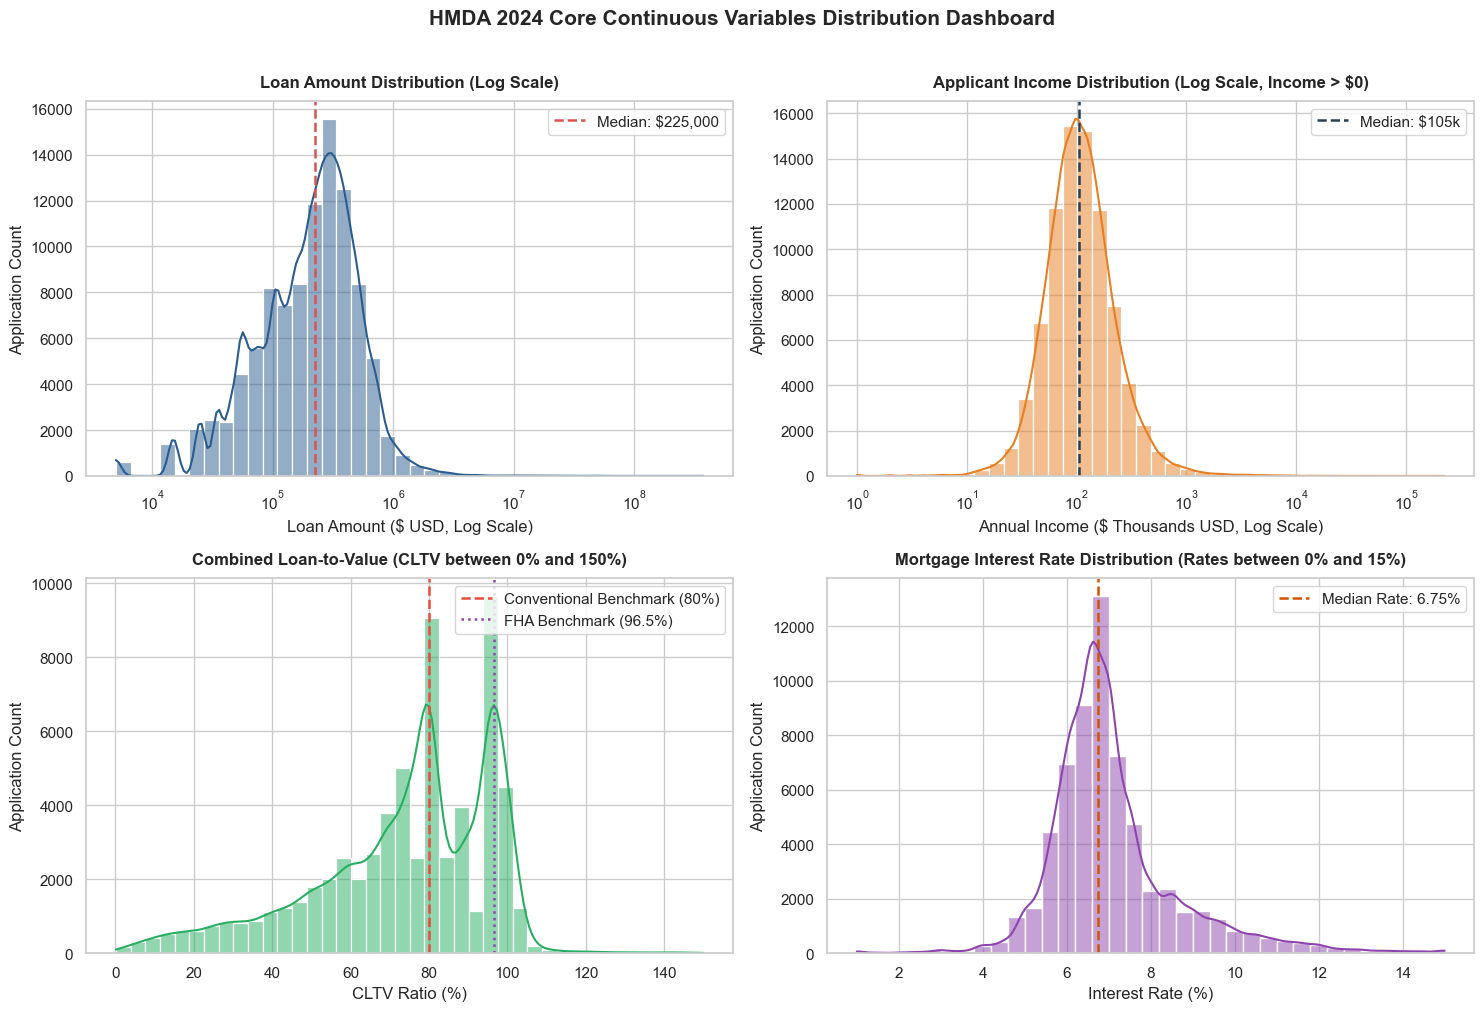

In [39]:
# Cell: Core Numerical Variables Distribution Dashboard (4-Panel Histograms)
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Trích xuất mẫu 100,000 hồ sơ từ bucket 0 để vẽ phân phối mượt mà và tức thì
sample_plot_sql = f"""
SELECT 
    try_cast(loan_amount AS DOUBLE) AS loan_amount,
    try_cast(income AS DOUBLE) AS income,
    try_cast(combined_loan_to_value_ratio AS DOUBLE) AS cltv,
    try_cast(interest_rate AS DOUBLE) AS interest_rate
FROM read_parquet('{parquet_path_str}')
WHERE bucket = 0
  AND loan_amount NOT IN {SENTINELS_NUM}
LIMIT 100000;
"""
df_plot = duck_conn.execute(sample_plot_sql).df()

# 2. Thiết lập bố cục lưới 2x2
sns.set_theme(style="whitegrid", font_scale=1.0)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# -------------------------------------------------------------------------
# Subplot 1: Loan Amount (Log Scale)
# -------------------------------------------------------------------------
df_la = df_plot[df_plot['loan_amount'] > 0]
sns.histplot(df_la['loan_amount'], log_scale=True, kde=True, ax=axes[0, 0], color='#2b5c8f', bins=40)
med_la = df_la['loan_amount'].median()
axes[0, 0].axvline(med_la, color='#d9534f', linestyle='--', linewidth=1.8, label=f'Median: ${med_la:,.0f}')
axes[0, 0].set_title('Loan Amount Distribution (Log Scale)', fontsize=12, fontweight='bold', pad=10)
axes[0, 0].set_xlabel('Loan Amount ($ USD, Log Scale)')
axes[0, 0].set_ylabel('Application Count')
axes[0, 0].legend(loc='upper right')

# -------------------------------------------------------------------------
# Subplot 2: Applicant Income (Log Scale, Income > 0)
# -------------------------------------------------------------------------
df_inc = df_plot[df_plot['income'] > 0]
sns.histplot(df_inc['income'], log_scale=True, kde=True, ax=axes[0, 1], color='#e67e22', bins=40)
med_inc = df_inc['income'].median()
axes[0, 1].axvline(med_inc, color='#2c3e50', linestyle='--', linewidth=1.8, label=f'Median: ${med_inc:,.0f}k')
axes[0, 1].set_title('Applicant Income Distribution (Log Scale, Income > $0)', fontsize=12, fontweight='bold', pad=10)
axes[0, 1].set_xlabel('Annual Income ($ Thousands USD, Log Scale)')
axes[0, 1].set_ylabel('Application Count')
axes[0, 1].legend(loc='upper right')

# -------------------------------------------------------------------------
# Subplot 3: Combined Loan-to-Value (CLTV in standard market range 0-150%)
# -------------------------------------------------------------------------
df_cltv = df_plot[(df_plot['cltv'] > 0) & (df_plot['cltv'] <= 150)]
sns.histplot(df_cltv['cltv'], kde=True, ax=axes[1, 0], color='#27ae60', bins=40)
axes[1, 0].axvline(80.0, color='#e74c3c', linestyle='--', linewidth=1.8, label='Conventional Benchmark (80%)')
axes[1, 0].axvline(96.5, color='#8e44ad', linestyle=':', linewidth=1.8, label='FHA Benchmark (96.5%)')
axes[1, 0].set_title('Combined Loan-to-Value (CLTV between 0% and 150%)', fontsize=12, fontweight='bold', pad=10)
axes[1, 0].set_xlabel('CLTV Ratio (%)')
axes[1, 0].set_ylabel('Application Count')
axes[1, 0].legend(loc='upper right')

# -------------------------------------------------------------------------
# Subplot 4: Interest Rate (Rates in realistic range 0-15%)
# -------------------------------------------------------------------------
df_rate = df_plot[(df_plot['interest_rate'] > 0) & (df_plot['interest_rate'] <= 15)]
sns.histplot(df_rate['interest_rate'], kde=True, ax=axes[1, 1], color='#8e44ad', bins=35)
med_rate = df_rate['interest_rate'].median()
axes[1, 1].axvline(med_rate, color='#d35400', linestyle='--', linewidth=1.8, label=f'Median Rate: {med_rate:.2f}%')
axes[1, 1].set_title('Mortgage Interest Rate Distribution (Rates between 0% and 15%)', fontsize=12, fontweight='bold', pad=10)
axes[1, 1].set_xlabel('Interest Rate (%)')
axes[1, 1].set_ylabel('Application Count')
axes[1, 1].legend(loc='upper right')

plt.suptitle('HMDA 2024 Core Continuous Variables Distribution Dashboard', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

## Section 8.1: Distribution Visualizations (Log Scale)

- **Input:** Sample of 100,000 valid applications from bucket 0.
- **Process:** Generate log-scale histograms with KDE overlays for `loan_amount` and `income` to inspect skewness and distinguish genuine jumbo loans from data entry errors.
- **Output:** Dual distribution visualization.

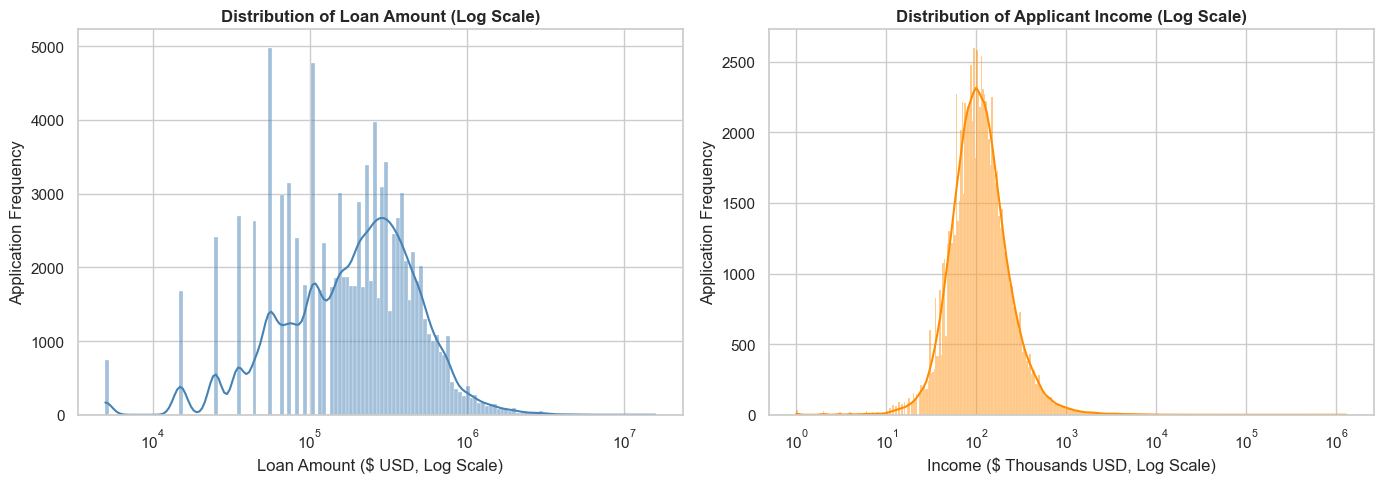

In [31]:
# Step 1: Sample 100,000 valid records for plotting distributions
sample_plot_sql = f"""
SELECT 
    try_cast(loan_amount AS DOUBLE) AS loan_amount,
    try_cast(income AS DOUBLE) AS income
FROM read_parquet('{parquet_path_str}')
WHERE bucket = 0 AND loan_amount NOT IN {SENTINELS_NUM} AND income NOT IN {SENTINELS_NUM}
  AND try_cast(loan_amount AS DOUBLE) > 0 AND try_cast(income AS DOUBLE) > 0
LIMIT 100000
"""
df_plot = duck_conn.execute(sample_plot_sql).df()

# Step 2: Plot log-scale distributions of Loan Amount and Applicant Income
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df_plot['loan_amount'], log_scale=True, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Distribution of Loan Amount (Log Scale)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Loan Amount ($ USD, Log Scale)')
axes[0].set_ylabel('Application Frequency')

sns.histplot(df_plot['income'], log_scale=True, kde=True, ax=axes[1], color='darkorange')
axes[1].set_title('Distribution of Applicant Income (Log Scale)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Income ($ Thousands USD, Log Scale)')
axes[1].set_ylabel('Application Frequency')

plt.tight_layout()
plt.show()
plt.close(fig)

## Section 9: Step 7 - Coverage & Representativeness

- **Input:** Raw Parquet dataset.
- **Process:** Evaluate geographic volume across states and lender concentration (market share held by top 10 institutions).
- **Output:** State and institutional concentration summary.

In [32]:
# Step 1: Query application counts by state (top 10 states)
state_cov_sql = f"""
SELECT 
    coalesce(state_code, 'Missing') AS state,
    COUNT(*) AS applications,
    COUNT(*) * 100.0 / {total_rows} AS market_share_pct
FROM read_parquet('{parquet_path_str}')
GROUP BY state_code
ORDER BY applications DESC
LIMIT 10
"""
top_states = duck_conn.execute(state_cov_sql).df()

# Step 2: Query top 10 lending institutions (by LEI) and their market concentration
lei_cov_sql = f"""
SELECT 
    lei,
    COUNT(*) AS applications,
    COUNT(*) * 100.0 / {total_rows} AS market_share_pct
FROM read_parquet('{parquet_path_str}')
GROUP BY lei
ORDER BY applications DESC
LIMIT 10
"""
top_lenders = duck_conn.execute(lei_cov_sql).df()
top10_share = top_lenders['market_share_pct'].sum()

# Step 3: Display results
print(f'Top 10 Lenders Combined Market Share: {top10_share:.2f}%\n')
display(top_states.head(5))
display(top_lenders.head(5))

Top 10 Lenders Combined Market Share: 24.00%



,state,applications,market_share_pct
0,TX,1074771,8.7671
1,FL,1047439,8.5441
2,CA,1026119,8.3702
3,NC,494607,4.0346
4,GA,478257,3.9012


,lei,applications,market_share_pct
0,549300FGXN1K3HLB1R50,553854,4.5179
1,549300HW662MN1WU8550,493978,4.0294
2,RVDPPPGHCGZ40J4VQ731,384816,3.1390
3,549300LYRWPSYPK6S325,252504,2.0597
4,549300FNXYY540N23N64,248242,2.0249


## Section 9.1: Demographic Sample Sizes & Baseline Denial Rates

- **Input:** Raw Parquet dataset.
- **Process:**
  - Document the pre-filter baseline distribution across all 9 `derived_race` categories.
  - To prevent mixed denominators, report: Total Applications, Share of Total Applications (%), Decision Sample Applications (`action_taken IN ('1','2','3')`), and Denial Rate on Decision Sample (%).
- **Output:** Pre-filter demographic baseline table.

In [33]:
# Step 1: Query full distribution across all 9 derived_race categories with explicit sample denominators
race_dist_sql = f"""
SELECT 
    derived_race,
    COUNT(*) AS total_applications,
    COUNT(*) * 100.0 / {total_rows} AS share_of_total_apps_pct,
    SUM(CASE WHEN action_taken IN ('1', '2', '3') THEN 1 ELSE 0 END) AS decision_sample_apps,
    SUM(CASE WHEN action_taken = '3' THEN 1 ELSE 0 END) * 100.0 / 
        NULLIF(SUM(CASE WHEN action_taken IN ('1', '2', '3') THEN 1 ELSE 0 END), 0) AS denial_rate_on_decision_sample_pct
FROM read_parquet('{parquet_path_str}')
GROUP BY derived_race
ORDER BY total_applications DESC
"""
race_dist_df = duck_conn.execute(race_dist_sql).df()

# Step 2: Format for display without requiring optional jinja2 dependency
disp_race = race_dist_df.copy()
disp_race['total_applications'] = disp_race['total_applications'].map('{:,}'.format)
disp_race['share_of_total_apps_pct'] = disp_race['share_of_total_apps_pct'].map('{:.2f}%'.format)
disp_race['decision_sample_apps'] = disp_race['decision_sample_apps'].map('{:,}'.format)
disp_race['denial_rate_on_decision_sample_pct'] = disp_race['denial_rate_on_decision_sample_pct'].map('{:.2f}%'.format)
display(disp_race)

,derived_race,total_applications,share_of_total_apps_pct,decision_sample_apps,denial_rate_on_decision_sample_pct
0,White,"6,952,490",56.71%,"5,550,877.0",21.81%
1,Race Not Available,"3,225,514",26.31%,"1,526,078.0",27.76%
2,Black or African American,"1,004,460",8.19%,"762,461.0",36.66%
3,Asian,"694,501",5.67%,"524,984.0",21.27%
4,Joint,"239,721",1.96%,"189,064.0",19.54%
5,American Indian or Alaska Native,"83,718",0.68%,"63,158.0",37.03%
6,2 or more minority races,"28,549",0.23%,"21,855.0",38.03%
7,Native Hawaiian or Other Pacific Islander,"27,208",0.22%,"21,118.0",38.70%
8,Free Form Text Only,"3,038",0.02%,"2,184.0",58.97%


## Section 10: Step 8 - Data Quality Audit Summary & Artifact Export

- **Input:** Aggregated audit metrics and detailed profile tables calculated across Steps 0 to 7.
- **Process:**
  - Consolidate overall audit metrics dynamically into an audit ledger table without hard-coded string literals.
  - Export the master quality summary plus all 8 specialized diagnostic tables (special codes, racial missingness, categorical validity, range violations, denial consistency, duplicates, percentiles, demographic baseline) to CSV files in `output/` for downstream cleaning rules to consume.
- **Output:** Persisted audit report and diagnostic tables in `output/` with file sizes and paths logged.

In [34]:
# Step 1: Consolidate core quality metrics into master ledger
quality_records = [
    {'Audit_Dimension': 'Ingest Integrity', 'Metric': 'Total Processed Applications', 'Value': f"{audit_row_count:,}", 'Benchmark_Status': 'Pass (100% Reconciled)' if audit_row_count == total_rows else 'Fail'},
    {'Audit_Dimension': 'Ingest Integrity', 'Metric': 'Column Completeness', 'Value': f'{audit_col_count} columns', 'Benchmark_Status': 'Pass' if audit_col_count == 101 else 'Fail'},
    {'Audit_Dimension': 'Special Codes', 'Metric': "Income Literal 'NA' Count", 'Value': f"{na_count:,}", 'Benchmark_Status': 'Preserved as string (T02)' if na_count > 0 else 'CHECK: no NA found'},
    {'Audit_Dimension': 'Validity (V01-V05)', 'Metric': 'Non-Positive Income Count', 'Value': f"{int(r_stats['flag_v02_income_le0']):,}", 'Benchmark_Status': 'To be flagged in cleaning (V02)'},
    {'Audit_Dimension': 'Validity (V01-V05)', 'Metric': 'Extreme/Invalid CLTV Count', 'Value': f"{int(r_stats['flag_v03_cltv_range']):,}", 'Benchmark_Status': 'To be flagged in cleaning (V03)'},
    {'Audit_Dimension': 'Duplicates (V10)', 'Metric': 'Extra Duplicate Rows', 'Value': f"{int(dup_stats['total_extra_copies']):,}", 'Benchmark_Status': 'To be flagged in cleaning (V10)'}
]
quality_report_df = pd.DataFrame(quality_records)

# Step 2: Export master summary and specialized diagnostic tables to output/
export_dict = {
    'B04_data_quality_report.csv': quality_report_df,
    'B04_special_codes_profile.csv': special_codes_df,
    'B04_race_missingness_profile.csv': race_missing_df,
    'B04_categorical_validity.csv': pd.DataFrame(cat_summary),
    'B04_numeric_range_violations.csv': range_audit_df,
    'B04_denial_consistency_crosstab.csv': denial_audit_df,
    'B04_duplicate_summary.csv': dup_report_df,
    'B04_financial_percentiles.csv': percentile_df,
    'B04_prefilter_demographic_baseline.csv': race_dist_df
}

print('Persisting diagnostic tables to output directory:')
for filename, df in export_dict.items():
    out_path = OUTPUT_DIR / filename
    df.to_csv(out_path, index=False)
    print(f'  -> {filename:38s} | {out_path.stat().st_size:6,d} bytes | Shape: {df.shape}')

display(quality_report_df)

Persisting diagnostic tables to output directory:
  -> B04_data_quality_report.csv            |    519 bytes | Shape: (6, 4)
  -> B04_special_codes_profile.csv          |    551 bytes | Shape: (10, 8)
  -> B04_race_missingness_profile.csv       |    831 bytes | Shape: (9, 5)
  -> B04_categorical_validity.csv           |    385 bytes | Shape: (7, 5)
  -> B04_numeric_range_violations.csv       |    336 bytes | Shape: (5, 4)
  -> B04_denial_consistency_crosstab.csv    |    385 bytes | Shape: (8, 6)
  -> B04_duplicate_summary.csv              |    280 bytes | Shape: (5, 2)
  -> B04_financial_percentiles.csv          |    367 bytes | Shape: (4, 10)
  -> B04_prefilter_demographic_baseline.csv |    779 bytes | Shape: (9, 5)


,Audit_Dimension,Metric,Value,Benchmark_Status
0,Ingest Integrity,Total Processed Applications,"12,259,199",Pass (100% Reconciled)
1,Ingest Integrity,Column Completeness,101 columns,Pass
2,Special Codes,Income Literal 'NA' Count,"1,780,434",Preserved as string (T02)
3,Validity (V01-V05),Non-Positive Income Count,"165,254",To be flagged in cleaning (V02)
4,Validity (V01-V05),Extreme/Invalid CLTV Count,"5,323",To be flagged in cleaning (V03)
5,Duplicates (V10),Extra Duplicate Rows,"26,755",To be flagged in cleaning (V10)


C:\Users\Admin\AppData\Local\Temp\ipykernel_26668\3773664390.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  bars1 = sns.barplot(
C:\Users\Admin\AppData\Local\Temp\ipykernel_26668\3773664390.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  bars2 = sns.barplot(


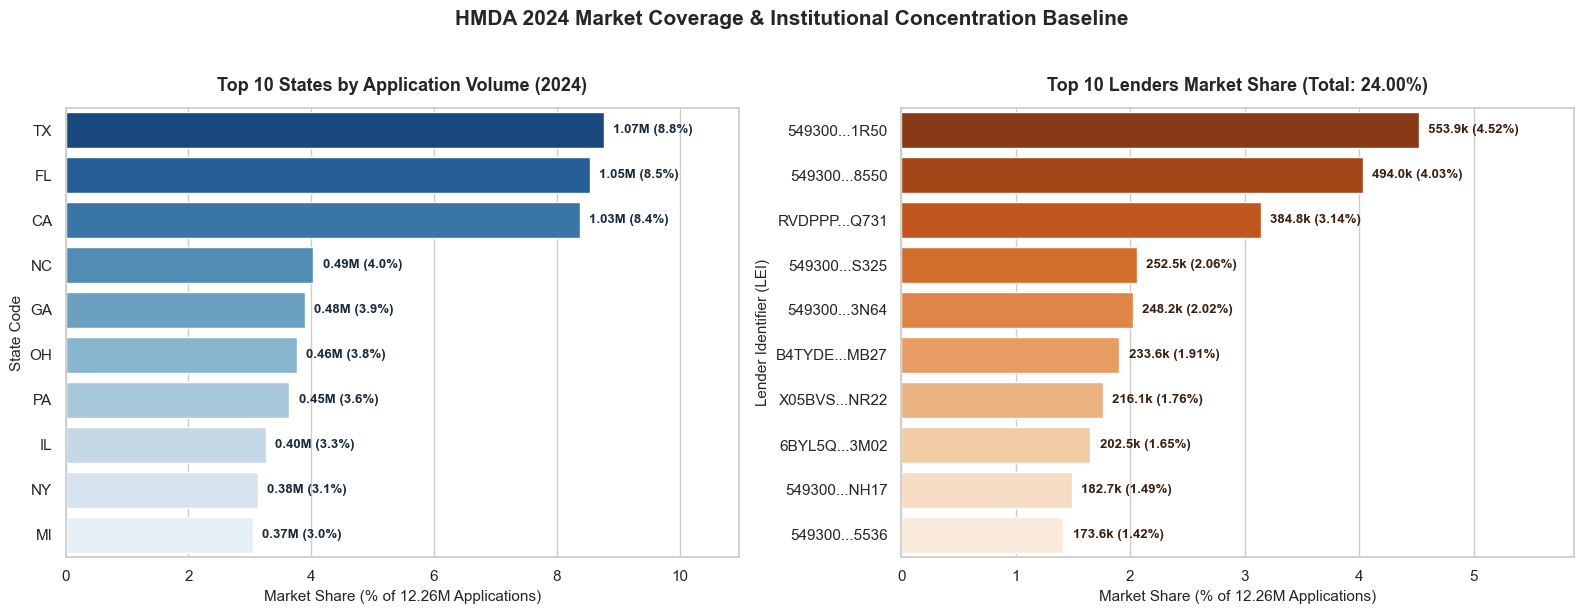

In [36]:

# Cell: Step 7 - Geographic and Institutional Coverage Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập phong cách hiển thị
sns.set_theme(style="whitegrid", font_scale=1.0)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# -------------------------------------------------------------------------
# Subplot 1: Top 10 States by Mortgage Application Market Share
# -------------------------------------------------------------------------
ax1 = axes[0]
bars1 = sns.barplot(
    data=top_states,
    x='market_share_pct',
    y='state',
    ax=ax1,
    palette='Blues_r'
)
ax1.set_title('Top 10 States by Application Volume (2024)', fontsize=13, fontweight='bold', pad=12)
ax1.set_xlabel('Market Share (% of 12.26M Applications)', fontsize=11)
ax1.set_ylabel('State Code', fontsize=11)
ax1.set_xlim(0, max(top_states['market_share_pct']) * 1.25)

# Hiển thị nhãn giá trị (Volume & Share) ở cuối mỗi cột
for bar, (_, row) in zip(bars1.patches, top_states.iterrows()):
    vol_millions = row['applications'] / 1_000_000
    pct = row['market_share_pct']
    ax1.text(
        bar.get_width() + 0.15,
        bar.get_y() + bar.get_height() / 2,
        f"{vol_millions:.2f}M ({pct:.1f}%)",
        va='center',
        ha='left',
        fontsize=9.5,
        fontweight='semibold',
        color='#1a2a3a'
    )

# -------------------------------------------------------------------------
# Subplot 2: Top 10 Lending Institutions (LEI Concentration)
# -------------------------------------------------------------------------
ax2 = axes[1]
# Rút gọn mã LEI (6 ký tự đầu...4 ký tự cuối) để trục Y không bị tràn chữ
top_lenders['short_lei'] = top_lenders['lei'].apply(lambda x: f"{x[:6]}...{x[-4:]}" if len(x) > 10 else x)

bars2 = sns.barplot(
    data=top_lenders,
    x='market_share_pct',
    y='short_lei',
    ax=ax2,
    palette='Oranges_r'
)
top10_share = top_lenders['market_share_pct'].sum()
ax2.set_title(f'Top 10 Lenders Market Share (Total: {top10_share:.2f}%)', fontsize=13, fontweight='bold', pad=12)
ax2.set_xlabel('Market Share (% of 12.26M Applications)', fontsize=11)
ax2.set_ylabel('Lender Identifier (LEI)', fontsize=11)
ax2.set_xlim(0, max(top_lenders['market_share_pct']) * 1.3)

# Hiển thị nhãn giá trị
for bar, (_, row) in zip(bars2.patches, top_lenders.iterrows()):
    vol_k = row['applications'] / 1_000
    pct = row['market_share_pct']
    ax2.text(
        bar.get_width() + 0.08,
        bar.get_y() + bar.get_height() / 2,
        f"{vol_k:.1f}k ({pct:.2f}%)",
        va='center',
        ha='left',
        fontsize=9.5,
        fontweight='semibold',
        color='#3a2010'
    )

plt.suptitle('HMDA 2024 Market Coverage & Institutional Concentration Baseline', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

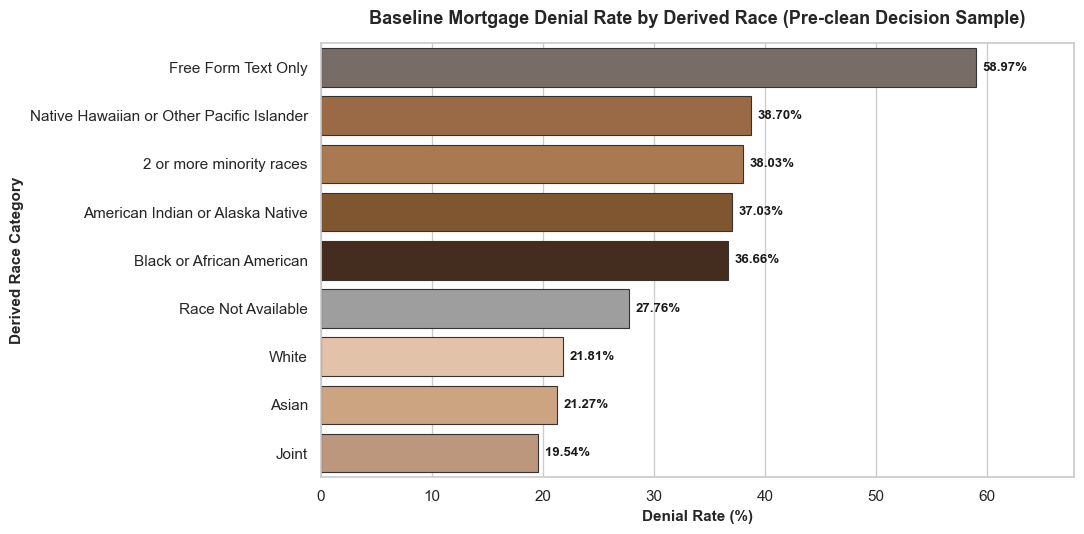

In [38]:
# Cell: Baseline Denial Rate by Derived Race with Realistic Skin Tone Palette
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Định nghĩa bảng màu sắc tố da tự nhiên (Human Skin Tone Spectrum)
skin_tone_palette = {
    'Black or African American': '#4A2C18',                  # Nâu sẫm ấm (Deep rich espresso)
    'American Indian or Alaska Native': '#8D5524',           # Nâu đồng ấm (Warm terracotta / copper)
    'Native Hawaiian or Other Pacific Islander': '#A86838',   # Nâu ánh đồng (Golden bronze)
    '2 or more minority races': '#B87842',                   # Nâu caramel ấm (Caramel amber)
    'Joint': '#C69472',                                      # Tông da pha trộn (Interracial co-applicants)
    'Asian': '#D9A376',                                      # Da châu Á tự nhiên (Warm almond / honey tan)
    'White': '#ECC0A0',                                      # Da sáng tự nhiên (Fair peachy-beige ivory)
    'Free Form Text Only': '#7A6B63',                        # Xám nâu trung tính (Custom text input)
    'Race Not Available': '#9E9E9E'                          # Xám trung tính (Missing / unclassified)
}

# 2. Chuẩn bị dữ liệu sắp xếp theo tỷ lệ từ chối giảm dần
plot_race = race_dist_df.dropna(subset=['denial_rate_on_decision_sample_pct']).sort_values(
    by='denial_rate_on_decision_sample_pct', ascending=False
)

# 3. Vẽ biểu đồ thanh ngang
plt.figure(figsize=(11, 5.5))
sns.set_theme(style="whitegrid", font_scale=1.0)

ax = sns.barplot(
    data=plot_race,
    x='denial_rate_on_decision_sample_pct',
    y='derived_race',
    hue='derived_race',
    palette=skin_tone_palette,
    legend=False,
    edgecolor='#333333',       # Viền mỏng giúp cột màu sáng không bị chìm
    linewidth=0.8
)

plt.title('Baseline Mortgage Denial Rate by Derived Race (Pre-clean Decision Sample)', 
          fontsize=13, fontweight='bold', pad=14)
plt.xlabel('Denial Rate (%)', fontsize=11, fontweight='semibold')
plt.ylabel('Derived Race Category', fontsize=11, fontweight='semibold')
plt.xlim(0, max(plot_race['denial_rate_on_decision_sample_pct']) * 1.15)

# 4. Hiển thị nhãn giá trị % rõ ràng ở đầu mỗi thanh
for bar in ax.patches:
    val = bar.get_width()
    ax.text(
        val + 0.6,
        bar.get_y() + bar.get_height() / 2,
        f"{val:.2f}%",
        va='center',
        ha='left',
        fontsize=9.5,
        fontweight='bold',
        color='#1a1a1a'
    )

plt.tight_layout()
plt.show()

## Executive Summary & Empirical Audit Findings

Execution of the 8-step data quality assessment across all 12,259,199 applications yields the following verified empirical baselines:

1. **Ingest Integrity & Traceability:**
   - **Volume & Dimensions:** Exactly 12,259,199 rows ingested into `output/B04_raw_with_buckets.parquet` (432.33 MB, ZSTD) across 101 columns (99 original fields + `row_id` + `bucket`).
   - **Schema Fidelity:** All 99 original fields are stored as string; all six post-ingest checks passed (Section 2.2).
   - **Partition Uniformity:** Bucket sizes are 122,591 or 122,592 records (maximum spread = 1).
   - **Header Reconciliation:** The CSV header matches the data dictionary 99/99 in both names and order.

2. **Completeness & Sentinel Mapping:**
   - **Blank strings:** exactly 0 in the audited columns, so missingness is expressed only through tokens.
   - **`income`:** 1,780,434 `'NA'` (14.52%) and 0 `'Exempt'`. The values 1111 (77 rows), 8888 (11 rows) and 9999 (27 rows) are treated as ordinary numeric incomes (in $000s) because `income` is numeric and shows no `'Exempt'` token. *[Hypothesis: unverified against HMDA documentation]*
   - **`debt_to_income_ratio`:** 4,060,236 `'NA'` (33.12%) and 287,240 `'Exempt'` (2.34%).
   - **Age fields:** `applicant_age` has 1,463,684 values of `8888`; `co_applicant_age` has 1,178,955 of `8888` and 6,666,402 of `9999`. Per the HMDA filing instructions cited in the data dictionary, 8888 = Not applicable and 9999 = No co-applicant.
   - **Exempt filers:** The count of `'Exempt'` / `1111` is about 287-288k across many fields (e.g. `debt_to_income_ratio`, `combined_loan_to_value_ratio`, `interest_rate`, `reverse_mortgage`). *[Hypothesis: these records come from lenders using partial exemptions under EGRRCPA]*

3. **Denial Consistency (The 1111 Clarification):**
   - Among 6,197,085 originated loans (`action_taken = 1`), 0 records carry a real denial reason (codes 1-9). The 174,669 records (2.82%) not coded `10` all carry `1111`.
   - Among 2,103,462 denied loans (`action_taken = 3`), 2,074,770 (98.64%) report reasons 1-9 and 28,692 (1.36%) report `1111`.

4. **Format & Range Violations (to be flagged in cleaning, not deleted):**
   - **V01 (`loan_amount <= 0`):** 0 records.
   - **V02 (`income <= 0`):** 165,254 records (1.35%): 157,494 exactly zero and 7,760 negative (small values such as -1 to -9). *[Hypothesis: zero or negative income reflects applicants whose income was not relied on, or business losses]*
   - **V03 (`CLTV <= 0` or `> 200`):** 5,323 records (0.04%).
   - **V04 (`interest_rate <= 0` or `> 25`):** 83,443 records (0.68%), of which 83,442 are `<= 0` (58,720 originated, 2,426 approved not accepted, 21,737 purchased, 559 preapproval approved) and 1 is above 25%.
   - **V05 (`loan_term` outside [1, 480]):** 2,893 records (0.02%).
   - **V06 (identifier format):** 0 violations for `lei` and `county_code` and `state_code`, and 1 violation for `census_tract`. Sentinel `NA` values: 349,023 in `census_tract` (2.85%), 296,190 in `county_code` (2.42%), 215,946 in `state_code` (1.76%).
   - **V07 (geographic hierarchy):** 0 mismatches at both the state and county prefix levels.

5. **Duplicate Clustering (Rule V10):**
   - 99-column MD5 hashing found 20,229 duplicate clusters covering 46,984 applications, i.e. 26,755 extra copies (0.22% of all rows). The largest cluster has 47 identical rows.
   - Duplicates remain in baseline sample S0 and will be flagged with `flag_dup_extra` in the cleaning stage, then excluded in robustness sample S1.

6. **Demographic Baseline & Missingness Disparities:**
   - **Decision-sample denial rates:** On 8,661,779 decisioned applications (`action_taken` in 1, 2, 3, before F02/F03), Black applicants have a 36.66% denial rate versus 21.81% for White applicants (+14.85 percentage points, unadjusted).
   - **"Race Not Available":** 1,526,078 applications (17.62% of the decision sample) with a 27.76% denial rate, 24.40% missing DTI and 19.19% missing income, well above other groups (DTI 3.75%-8.95%, income 1.51%-5.28%).
   - **CLTV missingness:** 10.02% (White), 12.75% (Black), 15.75% (American Indian or Alaska Native).

7. **Next Steps:**
   - Eight diagnostic profile tables plus the master ledger are saved in `output/` for downstream use.
   - Record decisions on V02 (zero or negative income) and V04 (zero interest rate) in `decisions.md`.
   - Proceed to Stage B (Data Cleaning & Preparation) to build `clean_all.parquet` using the Transformation (T), Validity (V) and Feature Engineering (X) rules in `data_cleaning_rules.md`.